Изначатьно задание я поняла так, что надо сделать два отдельных ноутбука, а потом при сдаче оказалось, что надо два, постаралась их склеить как могла

# Импорт библиотек

In [ ]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
pd.options.display.max_columns = 100
pd.options.display.max_rows = 64


sns.set_style("white")
sns.set_theme(style="whitegrid")


ASSETS_DIR = "../model_improvement/assets"
os.makedirs(ASSETS_DIR, exist_ok=True)

## Общий обзор датасета

In [3]:
df = pd.read_csv('../train_ver2.csv')

/tmp/ipykernel_130873/1788790913.py:1: DtypeWarning: Columns (5,8,11,15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../train_ver2.csv')


In [ ]:
df.describe()

,ncodpers,ind_nuevo,indrel,tipodom,cod_prov,ind_actividad_cliente,renta,ind_ahor_fin_ult1,ind_aval_fin_ult1,ind_cco_fin_ult1,...,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
count,1.364731e+07,1.361958e+07,1.361958e+07,13619574.0,1.355372e+07,1.361958e+07,1.085293e+07,1.364731e+07,1.364731e+07,1.364731e+07,...,1.364731e+07,1.364731e+07,1.364731e+07,1.364731e+07,1.364731e+07,1.364731e+07,1.364731e+07,1.363125e+07,1.363125e+07,1.364731e+07
mean,8.349042e+05,5.956184e-02,1.178399e+00,1.0,2.657147e+01,4.578105e-01,1.342543e+05,1.022912e-04,2.315475e-05,6.554837e-01,...,5.886582e-03,9.170965e-03,2.627404e-03,5.253636e-02,4.438868e-02,2.560761e-02,3.847718e-03,5.472434e-02,5.942854e-02,1.279162e-01
std,4.315650e+05,2.366733e-01,4.177469e+00,0.0,1.278402e+01,4.982169e-01,2.306202e+05,1.011340e-02,4.811883e-03,4.752103e-01,...,7.649791e-02,9.532502e-02,5.119083e-02,2.231060e-01,2.059571e-01,1.579616e-01,6.191053e-02,2.274414e-01,2.364250e-01,3.339965e-01
min,1.588900e+04,0.000000e+00,1.000000e+00,1.0,1.000000e+00,0.000000e+00,1.202730e+03,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.528130e+05,0.000000e+00,1.000000e+00,1.0,1.500000e+01,0.000000e+00,6.871098e+04,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,9.318930e+05,0.000000e+00,1.000000e+00,1.0,2.800000e+01,0.000000e+00,1.018500e+05,0.000000e+00,0.000000e+00,1.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,1.199286e+06,0.000000e+00,1.000000e+00,1.0,3.500000e+01,1.000000e+00,1.559560e+05,0.000000e+00,0.000000e+00,1.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,1.553689e+06,1.000000e+00,9.900000e+01,1.0,5.200000e+01,1.000000e+00,2.889440e+07,1.000000e+00,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [ ]:
df.head(5)

,fecha_dato,ncodpers,ind_empleado,pais_residencia,sexo,age,fecha_alta,ind_nuevo,antiguedad,indrel,ult_fec_cli_1t,indrel_1mes,tiprel_1mes,indresi,indext,conyuemp,canal_entrada,indfall,tipodom,cod_prov,nomprov,ind_actividad_cliente,renta,segmento,ind_ahor_fin_ult1,ind_aval_fin_ult1,ind_cco_fin_ult1,ind_cder_fin_ult1,ind_cno_fin_ult1,ind_ctju_fin_ult1,ind_ctma_fin_ult1,ind_ctop_fin_ult1,ind_ctpp_fin_ult1,ind_deco_fin_ult1,ind_deme_fin_ult1,ind_dela_fin_ult1,ind_ecue_fin_ult1,ind_fond_fin_ult1,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
0,2015-01-28,1375586,N,ES,H,35,2015-01-12,0.0,6,1.0,NaN,1.0,A,S,N,NaN,KHL,N,1.0,29.0,MALAGA,1.0,87218.10,02 - PARTICULARES,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
1,2015-01-28,1050611,N,ES,V,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,S,NaN,KHE,N,1.0,13.0,CIUDAD REAL,0.0,35548.74,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
2,2015-01-28,1050612,N,ES,V,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,13.0,CIUDAD REAL,0.0,122179.11,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
3,2015-01-28,1050613,N,ES,H,22,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHD,N,1.0,50.0,ZARAGOZA,0.0,119775.54,03 - UNIVERSITARIO,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
4,2015-01-28,1050614,N,ES,V,23,2012-08-10,0.0,35,1.0,NaN,1.0,A,S,N,NaN,KHE,N,1.0,50.0,ZARAGOZA,1.0,NaN,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0


In [10]:
print("Размер датасета (строки, столбцы):", df.shape)

print("\nПервые 10 строк:")
display(df.head(10))

print("\nИнформация о столбцах:")
df.info()

# Подсчёт пропусков по столбцам
missing_df = (
    df.isna()
    .sum()
    .reset_index()
    .rename(columns={"index": "column", 0: "n_missing"})
)
missing_df["missing_share"] = missing_df["n_missing"] / len(df)

print("\nСтолбцы с наибольшей долей пропусков:")
display(
    missing_df.sort_values("missing_share", ascending=False).head(20)
)

# Разделение на числовые и категориальные признаки
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("\nЧисловые признаки:")
print(numeric_cols)

print("\nКатегориальные признаки:")
print(categorical_cols)

# Базовые статистики по числовым признакам
print("\nОписательные статистики по числовым признакам:")
describe_num = df[numeric_cols].describe().transpose()
display(describe_num)

# Базовые статистики по категориальным признакам
if len(categorical_cols) > 0:
    print("\nОписательные статистики по категориальным признакам:")
    describe_cat = df[categorical_cols].describe().transpose()
    display(describe_cat)


Размер датасета (строки, столбцы): (13647309, 48)

Первые 10 строк:


,fecha_dato,ncodpers,ind_empleado,pais_residencia,sexo,age,fecha_alta,ind_nuevo,antiguedad,indrel,ult_fec_cli_1t,indrel_1mes,tiprel_1mes,indresi,indext,conyuemp,canal_entrada,indfall,tipodom,cod_prov,nomprov,ind_actividad_cliente,renta,segmento,ind_ahor_fin_ult1,ind_aval_fin_ult1,ind_cco_fin_ult1,ind_cder_fin_ult1,ind_cno_fin_ult1,ind_ctju_fin_ult1,ind_ctma_fin_ult1,ind_ctop_fin_ult1,ind_ctpp_fin_ult1,ind_deco_fin_ult1,ind_deme_fin_ult1,ind_dela_fin_ult1,ind_ecue_fin_ult1,ind_fond_fin_ult1,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
0,2015-01-28,1375586,N,ES,H,35,2015-01-12,0.0,6,1.0,NaN,1.0,A,S,N,NaN,KHL,N,1.0,29.0,MALAGA,1.0,87218.10,02 - PARTICULARES,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
1,2015-01-28,1050611,N,ES,V,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,S,NaN,KHE,N,1.0,13.0,CIUDAD REAL,0.0,35548.74,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
2,2015-01-28,1050612,N,ES,V,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,13.0,CIUDAD REAL,0.0,122179.11,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
3,2015-01-28,1050613,N,ES,H,22,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHD,N,1.0,50.0,ZARAGOZA,0.0,119775.54,03 - UNIVERSITARIO,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
4,2015-01-28,1050614,N,ES,V,23,2012-08-10,0.0,35,1.0,NaN,1.0,A,S,N,NaN,KHE,N,1.0,50.0,ZARAGOZA,1.0,NaN,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
5,2015-01-28,1050615,N,ES,H,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,45.0,TOLEDO,0.0,22220.04,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
6,2015-01-28,1050616,N,ES,H,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,24.0,LEON,0.0,295590.36,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
7,2015-01-28,1050617,N,ES,H,23,2012-08-10,0.0,35,1.0,NaN,1.0,A,S,N,NaN,KHE,N,1.0,50.0,ZARAGOZA,1.0,113316.66,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
8,2015-01-28,1050619,N,ES,H,24,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,20.0,GIPUZKOA,0.0,NaN,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0
9,2015-01-28,1050620,N,ES,H,23,2012-08-10,0.0,35,1.0,NaN,1.0,I,S,N,NaN,KHE,N,1.0,10.0,CACERES,0.0,113194.98,03 - UNIVERSITARIO,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0



Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13647309 entries, 0 to 13647308
Data columns (total 48 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   fecha_dato             object 
 1   ncodpers               int64  
 2   ind_empleado           object 
 3   pais_residencia        object 
 4   sexo                   object 
 5   age                    object 
 6   fecha_alta             object 
 7   ind_nuevo              float64
 8   antiguedad             object 
 9   indrel                 float64
 10  ult_fec_cli_1t         object 
 11  indrel_1mes            object 
 12  tiprel_1mes            object 
 13  indresi                object 
 14  indext                 object 
 15  conyuemp               object 
 16  canal_entrada          object 
 17  indfall                object 
 18  tipodom                float64
 19  cod_prov               float64
 20  nomprov                object 
 21  ind_actividad_cliente  float

,column,n_missing,missing_share
15,conyuemp,13645501,0.999868
10,ult_fec_cli_1t,13622516,0.998183
22,renta,2794375,0.204756
23,segmento,189368,0.013876
16,canal_entrada,186126,0.013638
11,indrel_1mes,149781,0.010975
12,tiprel_1mes,149781,0.010975
19,cod_prov,93591,0.006858
20,nomprov,93591,0.006858
4,sexo,27804,0.002037



Числовые признаки:
['ncodpers', 'ind_nuevo', 'indrel', 'tipodom', 'cod_prov', 'ind_actividad_cliente', 'renta', 'ind_ahor_fin_ult1', 'ind_aval_fin_ult1', 'ind_cco_fin_ult1', 'ind_cder_fin_ult1', 'ind_cno_fin_ult1', 'ind_ctju_fin_ult1', 'ind_ctma_fin_ult1', 'ind_ctop_fin_ult1', 'ind_ctpp_fin_ult1', 'ind_deco_fin_ult1', 'ind_deme_fin_ult1', 'ind_dela_fin_ult1', 'ind_ecue_fin_ult1', 'ind_fond_fin_ult1', 'ind_hip_fin_ult1', 'ind_plan_fin_ult1', 'ind_pres_fin_ult1', 'ind_reca_fin_ult1', 'ind_tjcr_fin_ult1', 'ind_valo_fin_ult1', 'ind_viv_fin_ult1', 'ind_nomina_ult1', 'ind_nom_pens_ult1', 'ind_recibo_ult1']

Категориальные признаки:
['fecha_dato', 'ind_empleado', 'pais_residencia', 'sexo', 'age', 'fecha_alta', 'antiguedad', 'ult_fec_cli_1t', 'indrel_1mes', 'tiprel_1mes', 'indresi', 'indext', 'conyuemp', 'canal_entrada', 'indfall', 'nomprov', 'segmento']

Описательные статистики по числовым признакам:


,count,mean,std,min,25%,50%,75%,max
ncodpers,13647309.0,834904.211501,431565.025784,15889.00,452813.00,931893.0,1199286.00,1553689.00
ind_nuevo,13619575.0,0.059562,0.236673,0.00,0.00,0.0,0.00,1.00
indrel,13619575.0,1.178399,4.177469,1.00,1.00,1.0,1.00,99.00
tipodom,13619574.0,1.000000,0.000000,1.00,1.00,1.0,1.00,1.00
cod_prov,13553718.0,26.571470,12.784017,1.00,15.00,28.0,35.00,52.00
ind_actividad_cliente,13619575.0,0.457811,0.498217,0.00,0.00,0.0,1.00,1.00
renta,10852934.0,134254.318238,230620.238822,1202.73,68710.98,101850.0,155955.96,28894395.51
ind_ahor_fin_ult1,13647309.0,0.000102,0.010113,0.00,0.00,0.0,0.00,1.00
ind_aval_fin_ult1,13647309.0,0.000023,0.004812,0.00,0.00,0.0,0.00,1.00
ind_cco_fin_ult1,13647309.0,0.655484,0.475210,0.00,0.00,1.0,1.00,1.00



Описательные статистики по категориальным признакам:


,count,unique,top,freq
fecha_dato,13647309,17,2016-05-28,931453
ind_empleado,13619575,5,N,13610977
pais_residencia,13619575,118,ES,13553710
sexo,13619505,2,V,7424252
age,13647309,235,23,542682
fecha_alta,13619575,6756,2014-07-28,57389
antiguedad,13647309,507,0,134335
ult_fec_cli_1t,24793,223,2015-12-24,763
indrel_1mes,13497528.0,13.0,1.0,7277607.0
tiprel_1mes,13497528,5,I,7304875


## Подготовка признаков для анализа

In [4]:
ID_COL = "ncodpers"
DATE_COL = "fecha_dato"
JOIN_DATE_COL = "fecha_alta"

# Продуктовые колонки (бинарные флаги наличия продуктов)
PRODUCT_COLS = sorted([c for c in df.columns if c.startswith("ind_") and c.endswith("_ult1")])

# Колонки, которые не участвуют в EDA признаков как "обычные" фичи
# date/id нужны отдельно для временных разрезов
not_eda_features = [ID_COL, DATE_COL] + PRODUCT_COLS

# Приведение типов для корректного анализа
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df[JOIN_DATE_COL] = pd.to_datetime(df[JOIN_DATE_COL], errors="coerce")

df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["antiguedad"] = pd.to_numeric(df["antiguedad"], errors="coerce")

# Колонки с экстремальной долей пропусков
# conyuemp и ult_fec_cli_1t почти полностью пустые, в EDA отдельно фиксируются как непригодные
high_missing_cols = ["conyuemp", "ult_fec_cli_1t"]

# Удаление колонок с почти полной пустотой из дальнейшего анализа признаков
df_eda = df.drop(columns=[c for c in high_missing_cols if c in df.columns]).copy()

# Числовые признаки (кроме id/date и продуктовых флагов)
numeric_cols = [
    c for c in df_eda.select_dtypes(include=["int64", "float64"]).columns
    if c not in not_eda_features
]

# Категориальные признаки (кроме id/date и продуктовых флагов)
categorical_cols = [
    c for c in df_eda.select_dtypes(include=["object", "category", "bool"]).columns
    if c not in not_eda_features
]

# Бинарные категориальные признаки
binary_cols = [
    c for c in categorical_cols
    if df_eda[c].dropna().nunique() == 2
]

# Многокатегориальные признаки
multi_cat_cols = [c for c in categorical_cols if c not in binary_cols]

print("Кол-во продуктовых колонок:", len(PRODUCT_COLS))
print("Примеры продуктовых колонок:", PRODUCT_COLS[:5], "...", PRODUCT_COLS[-5:])
print("Числовые признаки:", numeric_cols)
print("Категориальные признаки:", categorical_cols)
print("Бинарные признаки:", binary_cols)
print("Многокатегориальные признаки:", multi_cat_cols)

print("\nДиапазон дат:", df_eda[DATE_COL].min(), "—", df_eda[DATE_COL].max())
print("Уникальных месяцев:", df_eda[DATE_COL].dt.to_period("M").nunique())


Кол-во продуктовых колонок: 24
Примеры продуктовых колонок: ['ind_ahor_fin_ult1', 'ind_aval_fin_ult1', 'ind_cco_fin_ult1', 'ind_cder_fin_ult1', 'ind_cno_fin_ult1'] ... ['ind_reca_fin_ult1', 'ind_recibo_ult1', 'ind_tjcr_fin_ult1', 'ind_valo_fin_ult1', 'ind_viv_fin_ult1']
Числовые признаки: ['age', 'ind_nuevo', 'antiguedad', 'indrel', 'tipodom', 'cod_prov', 'ind_actividad_cliente', 'renta']
Категориальные признаки: ['ind_empleado', 'pais_residencia', 'sexo', 'indrel_1mes', 'tiprel_1mes', 'indresi', 'indext', 'canal_entrada', 'indfall', 'nomprov', 'segmento']
Бинарные признаки: ['sexo', 'indresi', 'indext', 'indfall']
Многокатегориальные признаки: ['ind_empleado', 'pais_residencia', 'indrel_1mes', 'tiprel_1mes', 'canal_entrada', 'nomprov', 'segmento']

Диапазон дат: 2015-01-28 00:00:00 — 2016-05-28 00:00:00
Уникальных месяцев: 17


,share_1,cnt_1
ind_cco_fin_ult1,0.655484,8945588.0
ind_ctop_fin_ult1,0.129008,1760616.0
ind_recibo_ult1,0.127916,1745712.0
ind_ecue_fin_ult1,0.082744,1129227.0
ind_cno_fin_ult1,0.080867,1103620.0
ind_nom_pens_ult1,0.059429,810085.0
ind_nomina_ult1,0.054724,745961.0
ind_reca_fin_ult1,0.052536,716980.0
ind_tjcr_fin_ult1,0.044389,605786.0
ind_ctpp_fin_ult1,0.043306,591008.0


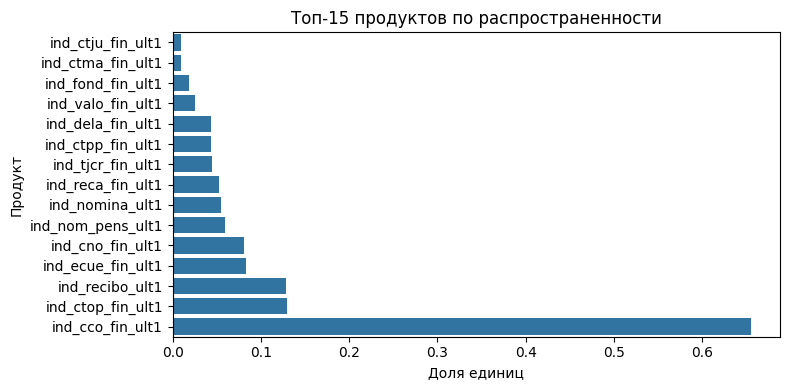

,value
count,300000.000000
mean,1.464247
std,1.513141
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,13.000000


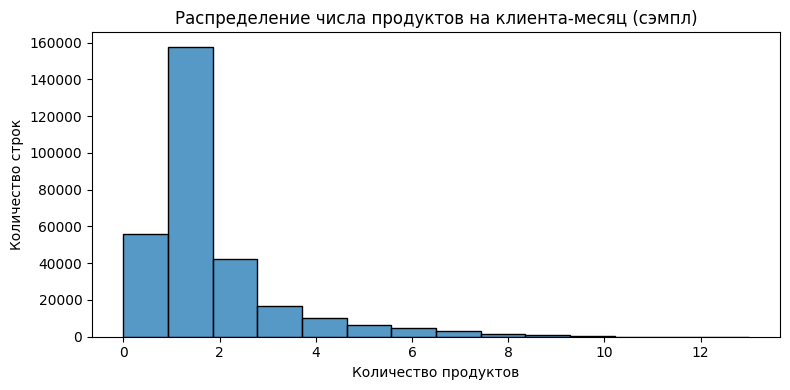

Доля строк, где у клиента есть хотя бы один продукт: 0.8127


In [7]:
# Продуктовые признаки: частоты и распределения

# Частоты владения продуктами (по всей таблице)
product_stats = (
    df_eda[PRODUCT_COLS]
    .agg(["mean", "sum"])
    .T
    .rename(columns={"mean": "share_1", "sum": "cnt_1"})
    .sort_values("share_1", ascending=False)
)

display(product_stats.head(10))
product_stats.to_csv(os.path.join(ASSETS_DIR, "product_prevalence.csv"), index=True)

# График: топ продуктов по доле единиц
top_n = 15
top_products = product_stats.head(top_n).iloc[::-1]

plt.figure(figsize=(8, 4))
sns.barplot(x=top_products["share_1"], y=top_products.index, orient="h")
plt.title(f"Топ-{top_n} продуктов по распространенности")
plt.xlabel("Доля единиц")
plt.ylabel("Продукт")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "top_products_prevalence.png"))
plt.show()

# Количество продуктов в строке (сэмпл, чтобы не создавать колонку на весь df_eda)
sample_size = 300_000
df_np = df_eda[PRODUCT_COLS].sample(n=min(sample_size, len(df_eda)), random_state=42)

n_products_sample = df_np.sum(axis=1).astype("int16")

display(n_products_sample.describe().to_frame(name="value"))
n_products_sample.describe().to_frame(name="value").to_csv(os.path.join(ASSETS_DIR, "n_products_describe_sample.csv"))

plt.figure(figsize=(8, 4))
sns.histplot(n_products_sample, bins=int(n_products_sample.max()) + 1)
plt.title("Распределение числа продуктов на клиента-месяц (сэмпл)")
plt.xlabel("Количество продуктов")
plt.ylabel("Количество строк")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "n_products_distribution_sample.png"))
plt.show()

# Доля строк с хотя бы одним продуктом (по всей таблице, но без сохранения колонки)
share_any_product = (df_eda[PRODUCT_COLS].sum(axis=1) > 0).mean()
print("Доля строк, где у клиента есть хотя бы один продукт:", round(float(share_any_product), 4))


,new_cnt
ind_recibo_ult1,153205
ind_nom_pens_ult1,84767
ind_nomina_ult1,73799
ind_cco_fin_ult1,69997
ind_tjcr_fin_ult1,69311
ind_cno_fin_ult1,37187
ind_ecue_fin_ult1,26378
ind_dela_fin_ult1,12707
ind_reca_fin_ult1,9238
ind_ctma_fin_ult1,7002


fecha_dato
2015-01        0
2015-02    31372
2015-03    32062
2015-04    30617
2015-05    26553
2015-06    41991
2015-07    33713
2015-08    29514
2015-09    35731
2015-10    39834
2015-11    35266
2015-12    42385
2016-01    31030
2016-02    49072
2016-03    35258
2016-04    33022
2016-05    35888
Freq: M, dtype: int64

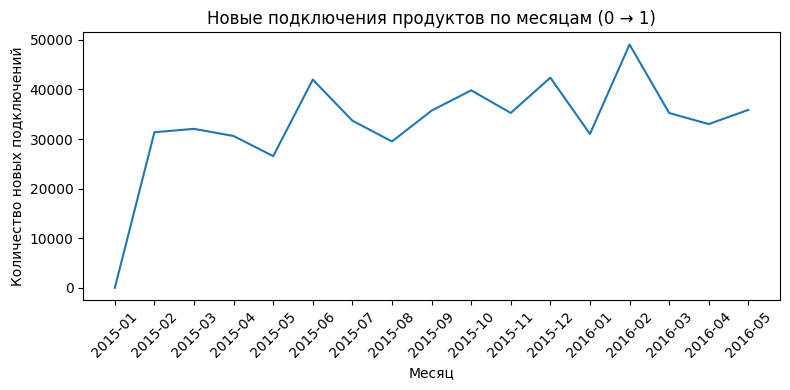

Доля строк с хотя бы одним новым продуктом: 0.0328


In [8]:
# Новые подключения продуктов (0 -> 1) и динамика по времени

df_sorted = df_eda[[ID_COL, DATE_COL] + PRODUCT_COLS].sort_values([ID_COL, DATE_COL])

# Лаги продуктовых флагов по клиенту
prev_products = df_sorted.groupby(ID_COL)[PRODUCT_COLS].shift(1)

# Новое подключение: было 0, стало 1
new_mask = (df_sorted[PRODUCT_COLS].eq(1) & prev_products.eq(0))

# Сколько новых подключений каждого продукта (итого за период)
new_product_stats = (
    new_mask.sum()
    .sort_values(ascending=False)
    .to_frame("new_cnt")
)

display(new_product_stats.head(10))
new_product_stats.to_csv(os.path.join(ASSETS_DIR, "new_product_counts_total.csv"), index=True)

# Сколько новых подключений в строке (в текущий клиент-месяц)
new_total_per_row = new_mask.sum(axis=1).astype("int16")

# Динамика по месяцам
new_per_month = (
    new_total_per_row
    .groupby(df_sorted[DATE_COL].dt.to_period("M"))
    .sum()
    .sort_index()
)

display(new_per_month)
new_per_month.to_csv(os.path.join(ASSETS_DIR, "new_products_per_month.csv"), index=True)

plt.figure(figsize=(8, 4))
sns.lineplot(x=new_per_month.index.astype(str), y=new_per_month.values)
plt.title("Новые подключения продуктов по месяцам (0 → 1)")
plt.xlabel("Месяц")
plt.ylabel("Количество новых подключений")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "new_products_per_month.png"))
plt.show()

# Доля строк с хотя бы одним новым продуктом
has_any_new = (new_total_per_row > 0).mean()
print("Доля строк с хотя бы одним новым продуктом:", round(float(has_any_new), 4))


Средняя вероятность нового продукта: 0.0328


has_new_product,mean_no_new,mean_with_new
age,40.118975,42.804858
ind_nuevo,0.057179,0.128745
antiguedad,79.171719,84.764879
indrel,1.179394,1.059514
tipodom,1.000000,1.000000
cod_prov,26.545266,26.844773
ind_actividad_cliente,0.439728,0.955668
renta,133562.361620,141351.419323


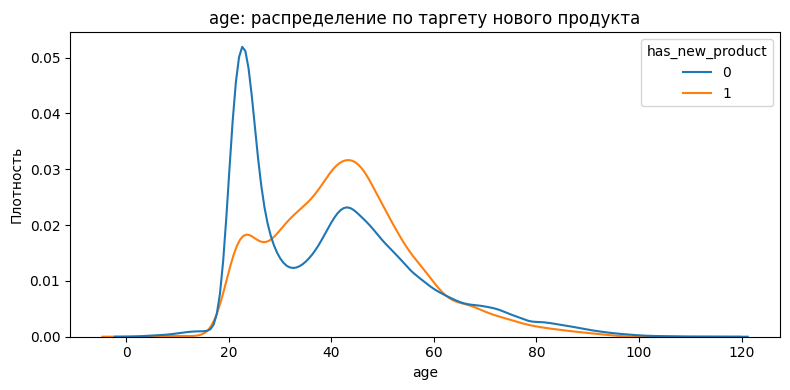

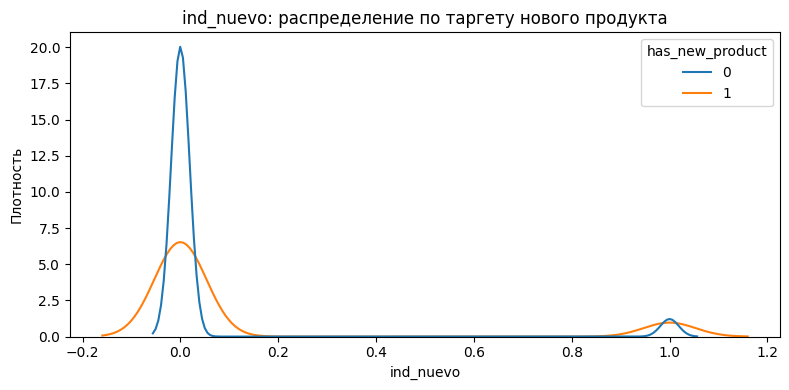

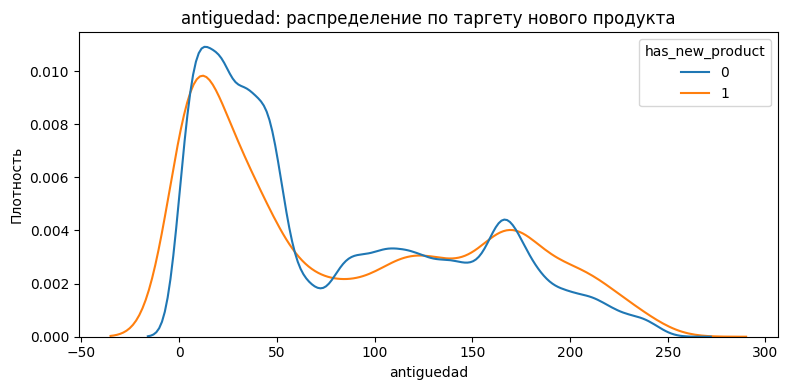

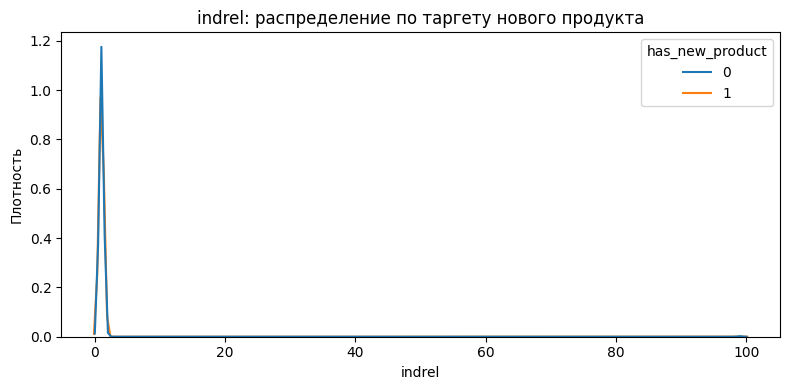

/tmp/ipykernel_130873/373961757.py:35: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


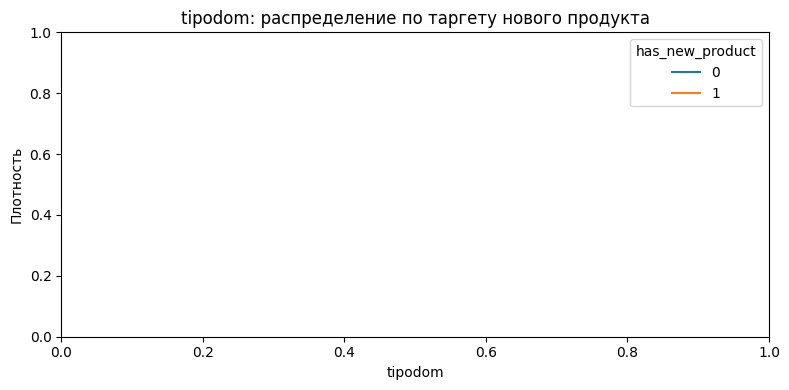

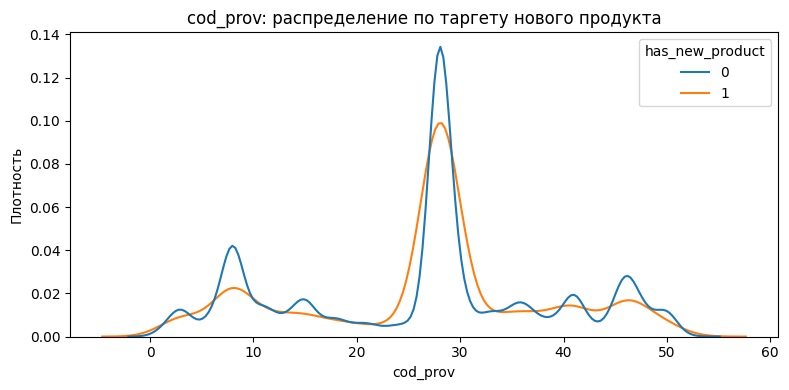

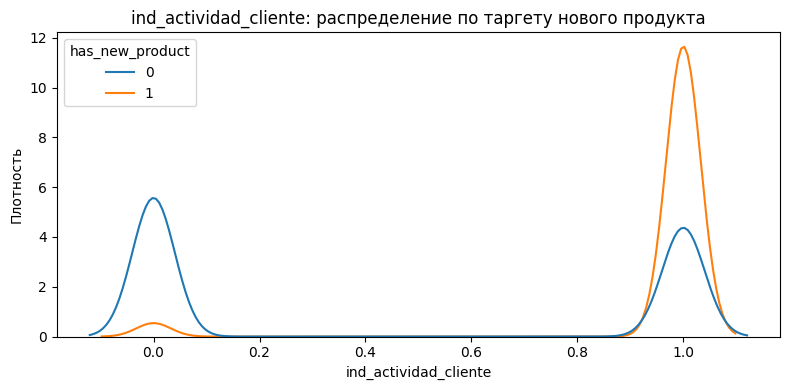

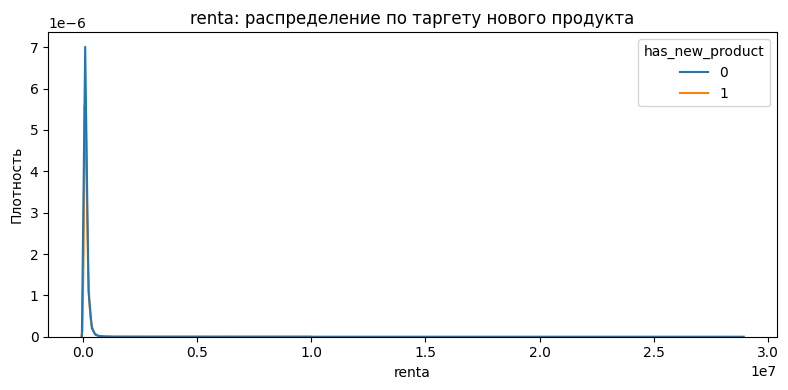

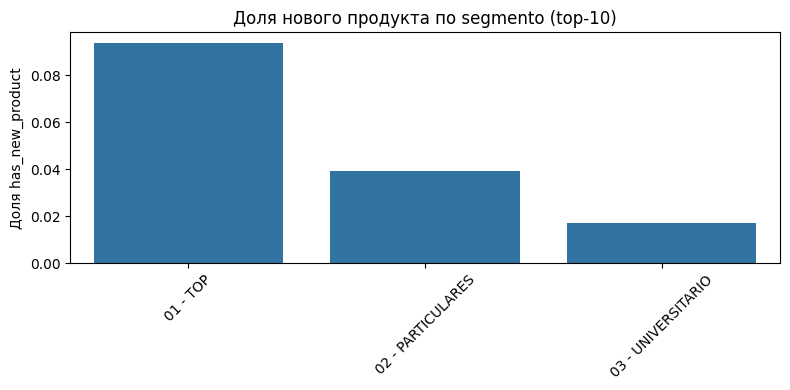

In [9]:
# Анализ клиентских признаков относительно новых продуктов

df_sorted = df_sorted.copy()
df_sorted["has_new_product"] = (new_total_per_row > 0).astype("int8")

target_rate = df_sorted["has_new_product"].mean()
print("Средняя вероятность нового продукта:", round(float(target_rate), 4))

# Для анализа признаков нужны клиентские признаки.
# Чтобы не тащить весь df_eda, берём сэмпл индексов из df_sorted и по ним подтягиваем признаки из df_eda.
sample_size = 300_000
sample_idx = df_sorted.index.to_series().sample(
    n=min(sample_size, len(df_sorted)),
    random_state=42
)

df_sample = df_eda.loc[sample_idx, numeric_cols + multi_cat_cols].copy()
df_sample["has_new_product"] = df_sorted.loc[sample_idx, "has_new_product"].values

# Средние по числовым признакам
numeric_feature_stats = (
    df_sample
    .groupby("has_new_product")[numeric_cols]
    .mean()
    .T
    .rename(columns={0: "mean_no_new", 1: "mean_with_new"})
)

display(numeric_feature_stats)
numeric_feature_stats.to_csv(os.path.join(ASSETS_DIR, "numeric_features_vs_new_product.csv"))

# Графики распределений числовых признаков (сэмпл)
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.kdeplot(
        data=df_sample,
        x=col,
        hue="has_new_product",
        common_norm=False
    )
    plt.title(f"{col}: распределение по таргету нового продукта")
    plt.xlabel(col)
    plt.ylabel("Плотность")
    plt.tight_layout()
    plt.savefig(os.path.join(ASSETS_DIR, f"{col}_by_target.png"))
    plt.show()

# Категориальные признаки: доля нового продукта по категориям (top-N)
top_n = 15
for col in multi_cat_cols:
    vc = df_sample[col].value_counts(dropna=False)
    top_vals = vc.head(top_n).index

    tmp = (
        df_sample[df_sample[col].isin(top_vals)]
        .groupby(col, dropna=False)["has_new_product"]
        .mean()
        .sort_values(ascending=False)
    )

    tmp.to_csv(os.path.join(ASSETS_DIR, f"{col}_target_rate_top{top_n}.csv"))

# Визуализация segmento (top-N, чтобы не падало)
col = "segmento"
vc = df_sample[col].value_counts(dropna=False)
top_vals = vc.head(10).index

plot_df = (
    df_sample[df_sample[col].isin(top_vals)]
    .groupby(col, dropna=False)["has_new_product"]
    .mean()
    .reset_index()
    .sort_values("has_new_product", ascending=False)
)

plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, x=col, y="has_new_product")
plt.title("Доля нового продукта по segmento (top-10)")
plt.xlabel("")
plt.ylabel("Доля has_new_product")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "segmento_new_product_rate_top10.png"))
plt.show()


### Корреляция числовых признаков


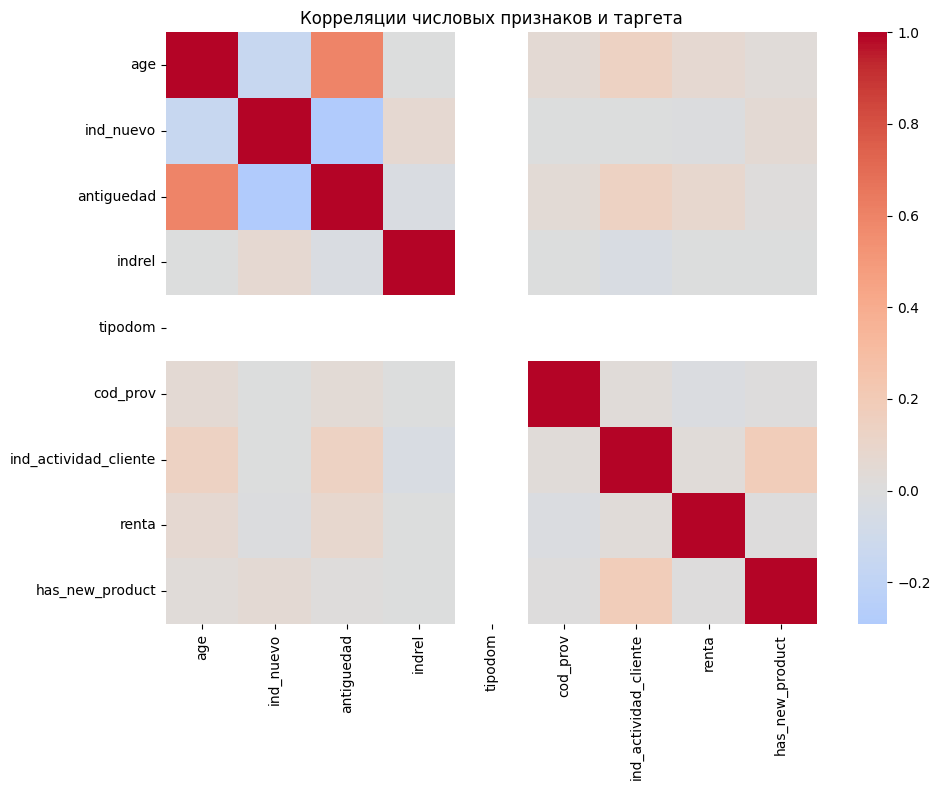

In [10]:
# Корреляции числовых признаков и таргета (на сэмпле)

corr_cols = numeric_cols + ["has_new_product"]

corr = df_sample[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=False,
    cmap="coolwarm",
    center=0
)

plt.title("Корреляции числовых признаков и таргета")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "numeric_correlation_heatmap.png"))
plt.show()


### Частоты значений бинарных признаков


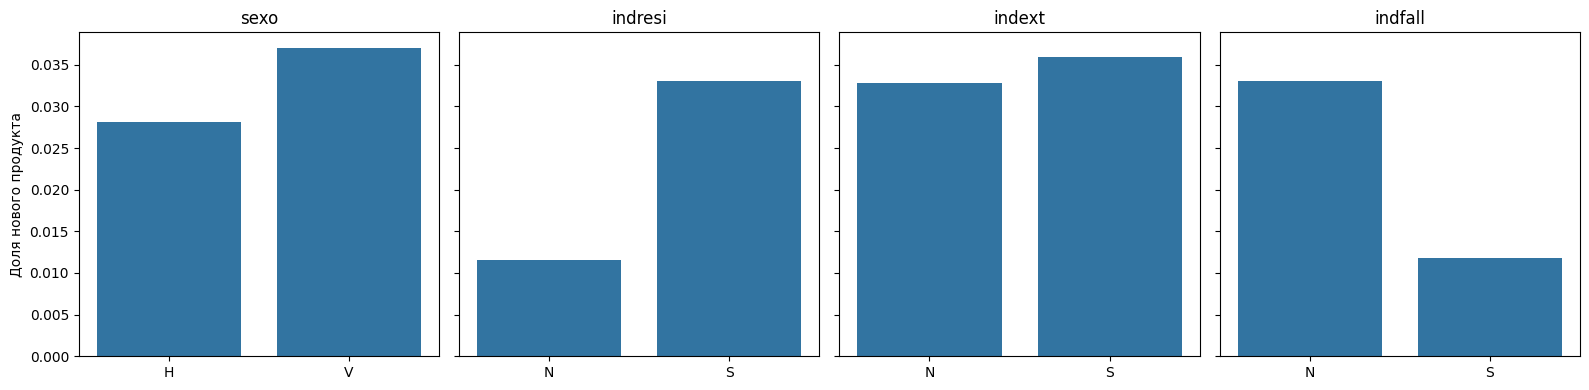

In [ ]:
binary_categorical_cols = ["sexo", "indresi", "indext", "indfall"]

df_sample_bin = df_eda.loc[sample_idx, binary_categorical_cols].copy()
df_sample_bin["has_new_product"] = df_sorted.loc[sample_idx, "has_new_product"].values

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(binary_categorical_cols),
    figsize=(4 * len(binary_categorical_cols), 4),
    sharey=True
)

for ax, col in zip(axes, binary_categorical_cols):
    plot_df = (
        df_sample_bin
        .groupby(col, as_index=False)["has_new_product"]
        .mean()
    )

    sns.barplot(data=plot_df, x=col, y="has_new_product", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Доля нового продукта")

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "binary_categorical_new_product_rate.png"))
plt.show()


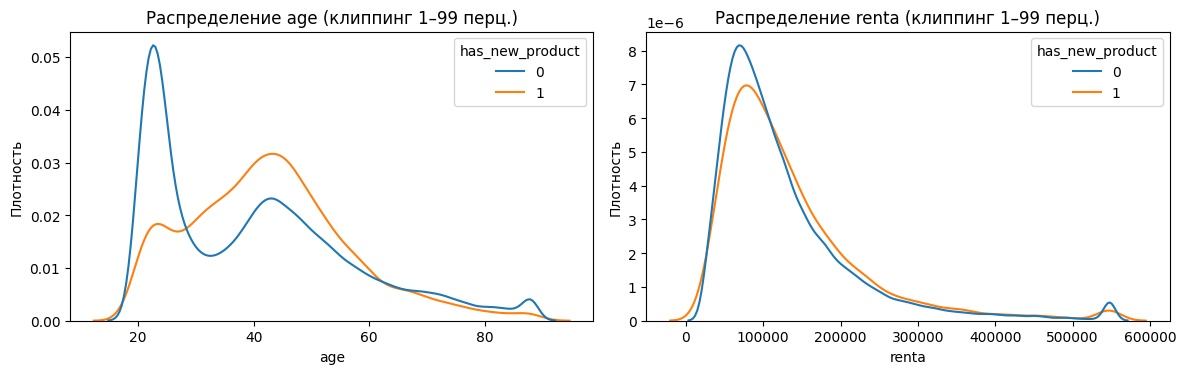

In [ ]:
# Распределения age и renta с клиппингом (1–99 перцентили) на сэмпле

clip_cols = ["age", "renta"]

df_sample_ar = df_eda.loc[sample_idx, clip_cols].copy()
df_sample_ar["has_new_product"] = df_sorted.loc[sample_idx, "has_new_product"].values

fig, axes = plt.subplots(nrows=1, ncols=len(clip_cols), figsize=(12, 4))

for ax, col in zip(axes, clip_cols):
    valid = df_sample_ar[col].dropna()
    q1, q99 = valid.quantile([0.01, 0.99])

    plot_df = df_sample_ar[[col, "has_new_product"]].dropna(subset=[col]).copy()
    plot_df[col] = plot_df[col].clip(lower=q1, upper=q99)

    sns.kdeplot(
        data=plot_df,
        x=col,
        hue="has_new_product",
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"Распределение {col} (клиппинг 1–99 перц.)")
    ax.set_xlabel(col)
    ax.set_ylabel("Плотность")

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "age_renta_clipped_distributions.png"))
plt.show()


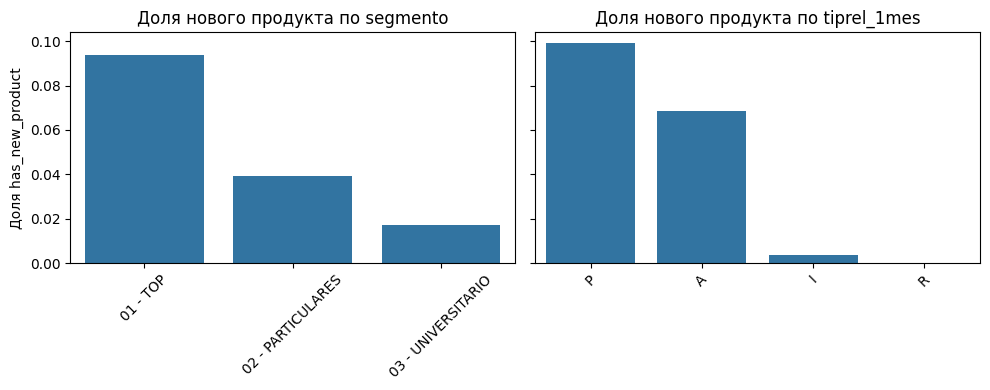

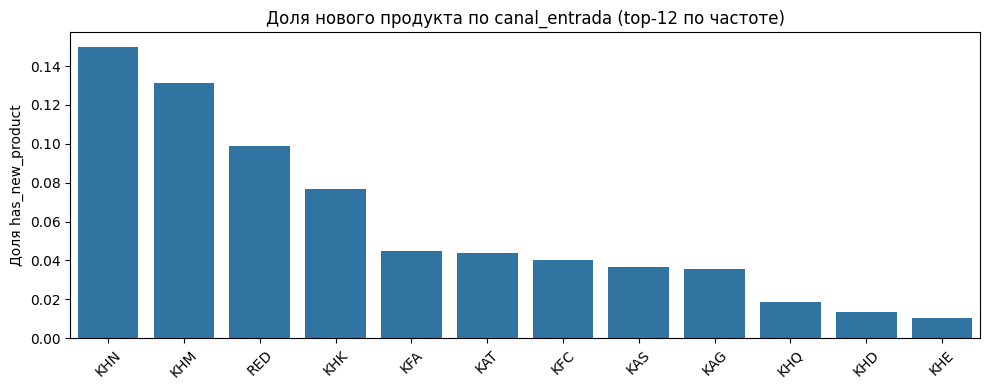

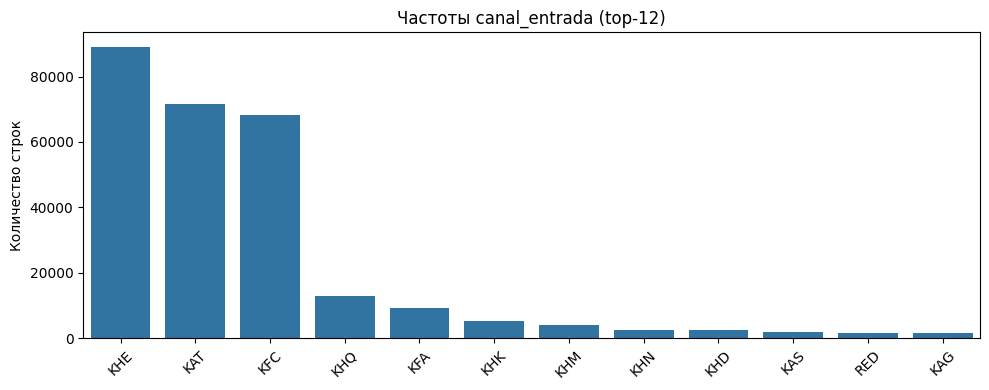

In [13]:
# Категориальные признаки: доля нового продукта

cat_cols = ["segmento", "tiprel_1mes"]

df_sample_cat = df_eda.loc[sample_idx, cat_cols + ["canal_entrada"]].copy()
df_sample_cat["has_new_product"] = df_sorted.loc[sample_idx, "has_new_product"].values

fig, axes = plt.subplots(nrows=1, ncols=len(cat_cols), figsize=(10, 4), sharey=True)

for ax, col in zip(axes, cat_cols):
    plot_df = (
        df_sample_cat
        .groupby(col, as_index=False)["has_new_product"]
        .mean()
        .sort_values("has_new_product", ascending=False)
    )

    sns.barplot(
        data=plot_df,
        x=col,
        y="has_new_product",
        ax=ax
    )

    ax.set_title(f"Доля нового продукта по {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Доля has_new_product")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "categorical_new_product_rate_segmento_tiprel.png"))
plt.show()

top_n = 12
top_canal = df_sample_cat["canal_entrada"].value_counts().head(top_n).index

canal_df = df_sample_cat[df_sample_cat["canal_entrada"].isin(top_canal)]

plot_df_rate = (
    canal_df
    .groupby("canal_entrada", as_index=False)["has_new_product"]
    .mean()
    .sort_values("has_new_product", ascending=False)
)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=plot_df_rate,
    x="canal_entrada",
    y="has_new_product"
)
plt.title(f"Доля нового продукта по canal_entrada (top-{top_n} по частоте)")
plt.xlabel("")
plt.ylabel("Доля has_new_product")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "canal_entrada_new_product_rate_topN.png"))
plt.show()


vc = df_sample_cat["canal_entrada"].value_counts().head(top_n)

plot_df_freq = vc.rename_axis("canal_entrada").reset_index(name="cnt")

plt.figure(figsize=(10, 4))
sns.barplot(
    data=plot_df_freq,
    x="canal_entrada",
    y="cnt"
)
plt.title(f"Частоты canal_entrada (top-{top_n})")
plt.xlabel("")
plt.ylabel("Количество строк")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "canal_entrada_freq_topN.png"))
plt.show()


<Figure size 1000x400 with 0 Axes>

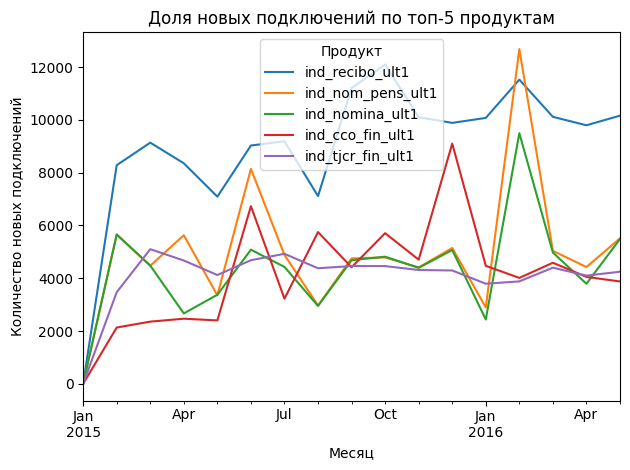

In [15]:
top_k = 5

new_long = (
    new_mask
    .assign(month=df_sorted[DATE_COL].dt.to_period("M"))
    .groupby("month")[PRODUCT_COLS]
    .sum()
)

top_products = new_long.sum().sort_values(ascending=False).head(top_k).index

plot_df = new_long[top_products]

plt.figure(figsize=(10, 4))
plot_df.plot()
plt.title("Доля новых подключений по топ-5 продуктам")
plt.xlabel("Месяц")
plt.ylabel("Количество новых подключений")
plt.legend(title="Продукт")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "top_products_new_by_month.png"))
plt.show()


# Выводы после EDA

EDA: выводы по данным и постановке задачи
1. Таргет: новые подключения продуктов (0 → 1)
- Новым подключением считается переход значения продуктового флага из 0 в 1 на уровне клиент–продукт–месяц.
- Общее количество новых подключений по месяцам после первого месяца стабильно, без деградации по времени.
- Доля клиентов с хотя бы одним новым продуктом в месяц находится в диапазоне ~3–5% и не демонстрирует выраженного тренда.
- Наблюдаются локальные пики новых подключений (в середине 2015 года и в начале 2016 года), что указывает на возможную сезонность или кампанийный эффект.
- Новые подключения распределены неравномерно по продуктам: небольшое число продуктов формирует основную долю всех 0→1 событий.

Вывод: таргет стабилен во времени, пригоден для временного разбиения и обучения рекомендательной модели без риска временного сдвига.

2. Продукты и структура каталога
- Каталог состоит из 24 продуктов с выраженной неравномерностью распространённости.
- Один продукт (ind_cco_fin_ult1) существенно доминирует по доле владения.
- Большинство клиентов в среднем имеют 1–2 продукта; далее наблюдается быстро убывающий хвост.
- Новые подключения также концентрируются в нескольких наиболее массовых продуктах.

Вывод: присутствует выраженный popularity bias, который необходимо учитывать при построении рекомендаций и выборе метрик.

3. Признаки: различия по факту нового продукта (EDA-индикатор)

3.1. Числовые признаки
- ind_actividad_cliente — наиболее сильный разделяющий признак; клиенты с новым продуктом существенно чаще активны.
- age — распределения различаются, группа с новым продуктом смещена.
- renta — различия присутствуют, но выражены умеренно; распределение с тяжёлым хвостом.
- antiguedad — форма распределений различается, эффект умеренный.
- ind_nuevo — информативен, различия между группами заметны.

3.2. Бинарные категориальные признаки
- sexo, indresi, indext, indfall — различия по доле нового продукта присутствуют, но не являются доминирующими.
- indfall демонстрирует заметный перепад долей.

3.3. Мультикатегориальные признаки
- segmento — выраженные различия: сегмент TOP имеет наибольшую долю новых подключений.
- tiprel_1mes — сильные различия между категориями (P, A против I, R).
- canal_entrada — сильный перекос по частотам и заметные различия по доле нового продукта; требует агрегации (top-N + other).

3.4. Малополезные признаки
- tipodom — практически константен, информативность низкая.
- indrel — распределение сильно сосредоточено в одной точке, полезность ограничена.

4. Корреляции числовых признаков
- Линейные корреляции числовых признаков с индикатором нового продукта в целом низкие.
- Наиболее заметная связь наблюдается у ind_actividad_cliente.
- Остальные признаки демонстрируют слабые или близкие к нулю корреляции.

Вывод: ожидается нелинейная и комбинированная зависимость, что обосновывает использование моделей ранжирования на основе градиентного бустинга.

5. Генерация дополнительных признаков (для ранжирования)

На основании EDA и ограничений проекта (объём данных, ресурсы виртуальной машины, требования к воспроизводимости и времени обучения) признаки были разделены на реализованные в проекте и потенциально возможные, но исключённые из реализации.

5.1. Реализованные признаки (используются в modeling)

5.1.1. История пользователя (t−1 snapshot)

Признаки рассчитываются на момент предыдущего месяца и используются как пользовательский контекст при ранжировании кандидатов:

- Количество продуктов у пользователя в предыдущем месяце

Отражает степень вовлечённости клиента и насыщенность продуктового портфеля.

- Флаг наличия нового подключения в предыдущем месяце

Учитывает эффект инерции: клиенты, недавно подключившие продукт, чаще совершают повторные подключения.

- Количество месяцев с новым подключением за последние 3 месяца

Характеризует краткосрочную динамику активности без использования длинных временных окон.

- Количество месяцев с последнего нового подключения

Отражает «давность» последней продуктовой активности пользователя.

Данные признаки:

- вычисляются один раз по обучающему периоду,
- не зависят от кандидатов,
- легко воспроизводимы в production-сценарии.

Месяц как категориальный признак (учёт сезонности).

5.2. Потенциальные признаки, не реализованные в проекте

Следующие группы признаков рассматривались и использововались, но не были оставлены осознанно в рамках данного проекта.

5.2.1. Признаки продукта

Частота новых подключений продукта (0→1). Частота новых подключений в скользящем временном окне (например, последние 3 месяца)

Причина исключения:
- ограниченный размер каталога (24 продукта),
- высокий риск усиления popularity bias,
- ограниченный вклад относительно уже используемых кандидатных стратегий.

5.2.2. Признаки пары пользователь–продукт

Co-occurrence продуктов на основе совместного владения. Суммарная и максимальная co-occurrence с текущим набором продуктов пользователя

Причина исключения:
- высокая вычислительная сложность,
- значительное потребление памяти,
- необходимость отдельного пайплайна расчёта и хранения матриц,
- отсутствие критической необходимости для демонстрации основного подхода.

5.2.3. Более сложные временные признаки

Длинные временные окна (6–12 месяцев). Временные тренды на уровне пользователя или продукта

Причина исключения:
- рост вычислительной стоимости,
- усложнение production-инференса,
- ограниченный прирост качества для учебного проекта.


6. Метрики качества рекомендаций

Основные
- Precision@k
- Recall@k
- Coverage@k по пользователям
- Coverage@k по продуктам

Дополнительные (при наличии времени)
- Novelty@k
- Diversity@k

Выбор метрик ориентирован на баланс между точностью рекомендаций и снижением popularity bias при ограниченном размере каталога.

# Логирование артефактов в MLflow

In [ ]:
import mlflow
from dotenv import load_dotenv
import os


load_dotenv(dotenv_path="../services/.env")

mlflow_s3_endpoint = os.getenv("MLFLOW_S3_ENDPOINT_URL")
aws_key_id = os.getenv("AWS_ACCESS_KEY_ID")
aws_secret = os.getenv("AWS_SECRET_ACCESS_KEY")

os.environ["MLFLOW_S3_ENDPOINT_URL"] = mlflow_s3_endpoint
os.environ["AWS_ACCESS_KEY_ID"] = aws_key_id
os.environ["AWS_SECRET_ACCESS_KEY"] = aws_secret

In [ ]:
from pathlib import Path

ASSETS_DIR = Path("../model_improvement/assets").resolve()

if not ASSETS_DIR.exists():
    raise FileNotFoundError(f"ASSETS_DIR not found: {ASSETS_DIR}")

# MLflow
TRACKING_URI = "http://localhost:5000"
EXPERIMENT_NAME = "bank_products_recsys"
RUN_NAME = "eda_artifacts"

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

with mlflow.start_run(run_name=RUN_NAME) as run:
    run_id = run.info.run_id

    # Логируем все файлы из assets в артефакты MLflow в папку eda/
    mlflow.log_artifacts(str(ASSETS_DIR), artifact_path="eda")

run_id


'4997a8278f6d475eaa5e7e79d7c33ed2'

Здесь можно сбрасывать ядро и запускать заново для экономия памяти

# Modeling

In [ ]:
import os
from pathlib import Path

import pickle
import json

import numpy as np
import pandas as pd

import mlflow
import mlflow.catboost
from mlflow.models.signature import infer_signature

from dotenv import load_dotenv
from catboost import CatBoostClassifier


import scipy.sparse as sp

# Настройки отображения
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

# Пути проекта
PROJECT_ROOT = Path("..").resolve()
DATA_PATH = PROJECT_ROOT / "train_ver2.csv"
ASSETS_DIR = PROJECT_ROOT / "model_improvement" / "assets"
ASSETS_DIR.mkdir(parents=True, exist_ok=True)

# Загрузка переменных окружения
load_dotenv(dotenv_path="./services/.env")

# Настройка окружения для MLflow + S3
mlflow_s3_endpoint = os.getenv("MLFLOW_S3_ENDPOINT_URL")
aws_key_id = os.getenv("AWS_ACCESS_KEY_ID")
aws_secret = os.getenv("AWS_SECRET_ACCESS_KEY")

if mlflow_s3_endpoint:
    os.environ["MLFLOW_S3_ENDPOINT_URL"] = mlflow_s3_endpoint
if aws_key_id:
    os.environ["AWS_ACCESS_KEY_ID"] = aws_key_id
if aws_secret:
    os.environ["AWS_SECRET_ACCESS_KEY"] = aws_secret

print("MLFLOW_S3_ENDPOINT_URL задан:", bool(mlflow_s3_endpoint))
print("AWS_ACCESS_KEY_ID задан:", bool(aws_key_id))
print("AWS_SECRET_ACCESS_KEY задан:", bool(aws_secret))

# MLflow
TRACKING_URI = "http://localhost:5000"
EXPERIMENT_NAME = "bank_products_recsys"
RUN_NAME = "stage4_experiments"

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)


MLFLOW_S3_ENDPOINT_URL задан: True
AWS_ACCESS_KEY_ID задан: True
AWS_SECRET_ACCESS_KEY задан: True


<Experiment: artifact_location='s3://<bucket>/3', creation_time=1770478486021, experiment_id='3', last_update_time=1770478486021, lifecycle_stage='active', name='bank_products_recsys', tags={}>

In [5]:
df = pd.read_csv(DATA_PATH)

/tmp/ipykernel_2601/2144582446.py:1: DtypeWarning: Columns (5,8,11,15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


### Константы и первичные преобразования

In [6]:
ID_COL = "ncodpers"
DATE_COL = "fecha_dato"
JOIN_DATE_COL = "fecha_alta"

# Продуктовые колонки
PRODUCT_COLS = sorted([c for c in df.columns if c.startswith("ind_") and c.endswith("_ult1")])

print("Строк:", len(df))
print("Уникальных клиентов:", df[ID_COL].nunique())
print("Продуктовых колонок:", len(PRODUCT_COLS))

# Приведение типов и базовые колонки времени
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df[JOIN_DATE_COL] = pd.to_datetime(df[JOIN_DATE_COL], errors="coerce")

df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["antiguedad"] = pd.to_numeric(df["antiguedad"], errors="coerce")

df["month"] = df[DATE_COL].dt.to_period("M").dt.to_timestamp()
df["month_str"] = df["month"].dt.strftime("%Y-%m")

print("Диапазон дат:", df[DATE_COL].min(), " ", df[DATE_COL].max())
print("Уникальных месяцев:", df["month"].nunique())

# Удаление колонок с почти полной пустотой
HIGH_MISSING_COLS = ["conyuemp", "ult_fec_cli_1t"]
drop_cols = [c for c in HIGH_MISSING_COLS if c in df.columns]
if drop_cols:
    df = df.drop(columns=drop_cols)
print("Удалены колонки:", drop_cols)

# Списки типов для дальнейшего использования
not_feature_cols = [ID_COL, DATE_COL, JOIN_DATE_COL, "month", "month_str"] + PRODUCT_COLS

NUMERIC_COLS = [
    c for c in df.select_dtypes(include=["int64", "float64"]).columns
    if c not in not_feature_cols
]

CATEGORICAL_COLS = [
    c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
    if c not in not_feature_cols
]

print("Числовых признаков:", len(NUMERIC_COLS))
print("Категориальных признаков:", len(CATEGORICAL_COLS))


Строк: 13647309
Уникальных клиентов: 956645
Продуктовых колонок: 24
Диапазон дат: 2015-01-28 00:00:00   2016-05-28 00:00:00
Уникальных месяцев: 17
Удалены колонки: ['conyuemp', 'ult_fec_cli_1t']
Числовых признаков: 8
Категориальных признаков: 11


### Уменьшение объема датафрейма

ядро всё время падает

In [7]:
import gc

np.random.seed(42)

N_USERS = 200_000
total_users = df[ID_COL].nunique()

users_sample = (
    df[[ID_COL]]
    .drop_duplicates()
    .sample(n=min(N_USERS, total_users), random_state=42)
)

# Фильтрация по списку пользователей через isin (быстрее и проще, чем merge)
df = df[df[ID_COL].isin(users_sample[ID_COL])].copy()

gc.collect()

print("Итог после сэмпла")
print("Строк:", len(df))
print("Пользователей:", df[ID_COL].nunique())
print("Уникальных месяцев:", df["month"].nunique())


Итог после сэмпла
Строк: 2852763
Пользователей: 200000
Уникальных месяцев: 17


# Построение baseline

# Разбиение данных

In [8]:
# Временное разбиение данных
SPLIT_DT = pd.to_datetime("2016-01-01")

df_train = df[df[DATE_COL] < SPLIT_DT].copy()
df_test = df[df[DATE_COL] >= SPLIT_DT].copy()

print("split_dt:", SPLIT_DT)

print("rows train:", len(df_train))
print("rows test :", len(df_test))

print("users train:", df_train[ID_COL].nunique())
print("users test :", df_test[ID_COL].nunique())

print("train date range:",
      df_train[DATE_COL].min(), df_train[DATE_COL].max())
print("test  date range:",
      df_test[DATE_COL].min(), df_test[DATE_COL].max())

print("train months:", df_train["month"].nunique())
print("test months :", df_test["month"].nunique())


split_dt: 2016-01-01 00:00:00
rows train: 1886729
rows test : 966034
users train: 193853
users test : 196134
train date range: 2015-01-28 00:00:00 2015-12-28 00:00:00
test  date range: 2016-01-28 00:00:00 2016-05-28 00:00:00
train months: 12
test months : 5


In [9]:
# Формирование событий user-product по train-периоду
events_train = (
    df_train[[ID_COL, "month"] + PRODUCT_COLS]
    .melt(
        id_vars=[ID_COL, "month"],
        var_name="product_id",
        value_name="value",
    )
)

# Оставляем только факты наличия продукта
events_train = events_train[events_train["value"] == 1].drop(columns=["value"])

print("events_train rows:", len(events_train))
print("users:", events_train[ID_COL].nunique())
print("products:", events_train["product_id"].nunique())
print("months:", events_train["month"].nunique())
print("date range:", events_train["month"].min(), events_train["month"].max())


events_train rows: 2887742
users: 148415
products: 24
months: 12
date range: 2015-01-01 00:00:00 2015-12-01 00:00:00


In [10]:
# Таргет: новые подключения продукта (0 -> 1)
LABEL_START_DT = pd.to_datetime("2015-12-01")
TARGET_START_DT = pd.to_datetime("2016-01-01")

df_label = df[df[DATE_COL] >= LABEL_START_DT].copy()
df_label = df_label.sort_values([ID_COL, "month"])

prev_products = df_label.groupby(ID_COL)[PRODUCT_COLS].shift(1)

new_products = (df_label[PRODUCT_COLS] == 1) & (prev_products == 0)

targets_pos = (
    new_products
    .assign(**{ID_COL: df_label[ID_COL].values, "month": df_label["month"].values})
    .melt(
        id_vars=[ID_COL, "month"],
        var_name="product_id",
        value_name="target",
    )
)

targets_pos = targets_pos[targets_pos["target"]].drop(columns=["target"])
targets_pos["target"] = 1
targets_pos = targets_pos[targets_pos["month"] >= TARGET_START_DT].copy()

print("positive targets:", len(targets_pos))
print("users:", targets_pos[ID_COL].nunique())
print("products:", targets_pos["product_id"].nunique())
print("months:", targets_pos["month"].nunique())


positive targets: 38939
users: 22629
products: 21
months: 5


In [11]:
# Кандидаты по популярности (top-N) и подготовка отрицательных примеров
# month уже рассчитан в df_test, повторно не считаем

print("Расчёт популярности продуктов по train-периоду")
product_popularity = (
    events_train["product_id"]
    .value_counts()
    .rename("cnt")
    .reset_index()
    .rename(columns={"product_id": "product_id"})
)

TOP_N = 10
top_products = product_popularity.head(TOP_N)["product_id"].tolist()
print("TOP_N:", TOP_N)
print("Топ продуктов для кандидатов:", top_products)

print("Формирование user-month для 2016")
users_months = df_test[[ID_COL, "month"]].drop_duplicates()
print("user-month строк:", len(users_months))
print("Пользователей:", users_months[ID_COL].nunique())
print("Месяцев:", users_months["month"].nunique())

print("Декартово произведение user-month x top_products")
top_df = pd.DataFrame({"product_id": top_products})
users_months["key"] = 1
top_df["key"] = 1

candidates = users_months.merge(top_df, on="key", how="inner").drop(columns=["key"])
users_months.drop(columns=["key"], inplace=True)
top_df.drop(columns=["key"], inplace=True)

print("Кандидатов всего:", len(candidates))

print("Разметка target по targets_pos")
pos_keys = targets_pos[[ID_COL, "month", "product_id"]].drop_duplicates()
pos_keys["target"] = 1

rank_df = candidates.merge(pos_keys, on=[ID_COL, "month", "product_id"], how="left")
rank_df["target"] = rank_df["target"].fillna(0).astype("int8")

print("Размер rank_df:", rank_df.shape)
print("Доля target=1:", round(float(rank_df["target"].mean()), 6))
print("Пользователей:", rank_df[ID_COL].nunique())
print("Месяцев:", rank_df["month"].nunique())
print("Продуктов:", rank_df["product_id"].nunique())


Расчёт популярности продуктов по train-периоду
TOP_N: 10
Топ продуктов для кандидатов: ['ind_cco_fin_ult1', 'ind_ctop_fin_ult1', 'ind_recibo_ult1', 'ind_ecue_fin_ult1', 'ind_cno_fin_ult1', 'ind_nom_pens_ult1', 'ind_nomina_ult1', 'ind_reca_fin_ult1', 'ind_tjcr_fin_ult1', 'ind_dela_fin_ult1']
Формирование user-month для 2016
user-month строк: 966034
Пользователей: 196134
Месяцев: 5
Декартово произведение user-month x top_products


Кандидатов всего: 9660340
Разметка target по targets_pos
Размер rank_df: (9660340, 4)
Доля target=1: 0.003895
Пользователей: 196134
Месяцев: 5
Продуктов: 10


In [ ]:
# TOP_K используем только для метрик и инференса
TOP_K = 5

print("Добавление score_pop и служебных признаков")

# score_pop считаем один раз по product_popularity
score_pop = (
    product_popularity
    .assign(score_pop=lambda x: x["cnt"] / x["cnt"].max())
    .loc[lambda x: x["product_id"].isin(top_products), ["product_id", "score_pop"]]
)

# merge score_pop
rank_df = rank_df.merge(score_pop, on="product_id", how="left")
rank_df["score_pop"] = rank_df["score_pop"].fillna(0.0).astype("float32")

# категориальные признаки
rank_df["product_id"] = rank_df["product_id"].astype("category")
rank_df["month_str"] = rank_df["month"].dt.strftime("%Y-%m").astype("category")

print("Итоговая таблица для ранжирования")
print("Размер rank_df:", rank_df.shape)
print("Доля target=1:", round(float(rank_df["target"].mean()), 6))
print("Пользователей:", rank_df[ID_COL].nunique())
print("Месяцев:", rank_df["month"].nunique())
print("Продуктов:", rank_df["product_id"].nunique())


Добавление score_pop и служебных признаков
Итоговая таблица для ранжирования
Размер rank_df: (9660340, 6)
Доля target=1: 0.003895
Пользователей: 196134
Месяцев: 5
Продуктов: 10


In [13]:
print("Добавление позитивов вне top-N")

pos_all = targets_pos[[ID_COL, "month", "product_id"]].drop_duplicates()
pos_all["target"] = 1

# добавляем позитивы, которых нет в candidate set
rank_df = pd.concat(
    [rank_df, pos_all],
    ignore_index=True,
).drop_duplicates(subset=[ID_COL, "month", "product_id"], keep="first")

# пересчитать target по объединению
rank_df["target"] = rank_df["target"].fillna(0).astype("int8")

print("Размер rank_df после добавления позитивов:", rank_df.shape)
print("Продуктов:", rank_df["product_id"].nunique())
print("Доля target=1:", round(float(rank_df["target"].mean()), 6))


Добавление позитивов вне top-N


Размер rank_df после добавления позитивов: (9661654, 6)
Продуктов: 21
Доля target=1: 0.00403


In [14]:
# Сплит по времени внутри 2016: последний месяц берётся как valid
months_sorted = sorted(rank_df["month"].unique())
valid_month = months_sorted[-1]
rank_df["month_str"] = rank_df["month"].dt.strftime("%Y-%m")


train_df = rank_df[rank_df["month"] < valid_month].copy()
valid_df = rank_df[rank_df["month"] == valid_month].copy()

print("Месяц валидации:", valid_month)
print("train:", train_df.shape, "valid:", valid_df.shape)
print("Доля target=1 train:", round(float(train_df["target"].mean()), 6))
print("Доля target=1 valid:", round(float(valid_df["target"].mean()), 6))


Месяц валидации: 2016-05-01 00:00:00
train: (7714744, 6) valid: (1946910, 6)
Доля target=1 train: 0.004056
Доля target=1 valid: 0.003929


In [ ]:
def evaluate_topk(
    valid_scored,
    top_k,
    id_col,
    month_col="month",
    product_col="product_id",
    target_col="target",
):
    # valid_scored должен содержать колонки: id_col, month_col, product_col, target_col, pred
    # pred это вероятность, следовательно, чем больше, тем выше в ранге

    df_eval = valid_scored[[id_col, month_col, product_col, target_col, "pred"]].copy()

    df_eval = df_eval.sort_values(
        [id_col, month_col, "pred"], ascending=[True, True, False]
    )
    df_eval["rank"] = df_eval.groupby([id_col, month_col]).cumcount() + 1

    topk_df = df_eval[df_eval["rank"] <= top_k].copy()

    gt = (
        df_eval[df_eval[target_col] == 1]
        .groupby([id_col, month_col])[product_col]
        .apply(set)
    )

    pred_sets = topk_df.groupby([id_col, month_col])[product_col].apply(list)

    # all: по всем user-month, где есть рекомендации
    precisions_all = []
    recalls_all = []

    for key, recs in pred_sets.items():
        true_set = gt.get(key, set())
        hit = len(set(recs) & true_set)
        precisions_all.append(hit / top_k)
        recalls_all.append(hit / max(1, len(true_set)))

    precision_all = float(np.mean(precisions_all)) if precisions_all else 0.0
    recall_all = float(np.mean(recalls_all)) if recalls_all else 0.0

    # pos: только user-month, где есть хотя бы один позитив
    precisions_pos = []
    recalls_pos = []

    pos_keys = set(gt.index)
    for key, recs in pred_sets.items():
        if key not in pos_keys:
            continue
        true_set = gt.get(key, set())
        hit = len(set(recs) & true_set)
        precisions_pos.append(hit / top_k)
        recalls_pos.append(hit / max(1, len(true_set)))

    precision_pos = float(np.mean(precisions_pos)) if precisions_pos else 0.0
    recall_pos = float(np.mean(recalls_pos)) if recalls_pos else 0.0

    total_user_month = df_eval[[id_col, month_col]].drop_duplicates().shape[0]
    coverage_users = (
        float(len(pred_sets) / total_user_month) if total_user_month else 0.0
    )
    coverage_items = (
        float(topk_df[product_col].nunique() / df_eval[product_col].nunique())
        if len(df_eval)
        else 0.0
    )

    return {
        "precision_at_k_all": precision_all,
        "recall_at_k_all": recall_all,
        "precision_at_k_pos": precision_pos,
        "recall_at_k_pos": recall_pos,
        "coverage_users": coverage_users,
        "coverage_items": coverage_items,
        "topk_df": topk_df,
        "pred_sets": pred_sets,
        "gt": gt,
    }

In [16]:
FEATURES = ["score_pop", "month_str", "product_id"]
CAT_FEATURES = ["month_str", "product_id"]

X_train = train_df[FEATURES].copy()
y_train = train_df["target"].astype("int8").copy()

X_valid = valid_df[FEATURES].copy()
y_valid = valid_df["target"].astype("int8").copy()

model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.1,
    depth=6,
    loss_function="Logloss",
    eval_metric="Logloss",
    random_seed=42,
    verbose=50,
)

print("Обучение CatBoost")
model.fit(
    X_train, y_train,
    cat_features=CAT_FEATURES,
    eval_set=(X_valid, y_valid),
)


Обучение CatBoost
0:	learn: 0.4575111	test: 0.4574404	best: 0.4574404 (0)	total: 2.25s	remaining: 11m 13s
50:	learn: 0.0241361	test: 0.0243547	best: 0.0237691 (35)	total: 2m 3s	remaining: 10m 5s
100:	learn: 0.0241072	test: 0.0268140	best: 0.0237691 (35)	total: 3m 40s	remaining: 7m 14s
150:	learn: 0.0241000	test: 0.0281562	best: 0.0237691 (35)	total: 5m 10s	remaining: 5m 5s
200:	learn: 0.0240929	test: 0.0292836	best: 0.0237691 (35)	total: 6m 45s	remaining: 3m 19s
250:	learn: 0.0240903	test: 0.0294612	best: 0.0237691 (35)	total: 8m 18s	remaining: 1m 37s
299:	learn: 0.0240902	test: 0.0294034	best: 0.0237691 (35)	total: 9m 46s	remaining: 0us

bestTest = 0.02376905488
bestIteration = 35

Shrink model to first 36 iterations.


In [17]:
print("Скоринг валидации")
valid_scored = valid_df[[ID_COL, "month", "product_id", "target"]].copy()
valid_scored["pred"] = model.predict_proba(X_valid)[:, 1].astype("float32")

metrics = evaluate_topk(valid_scored, TOP_K, ID_COL)

print("Precision@k (all):", round(metrics["precision_at_k_all"], 6))
print("Recall@k    (all):", round(metrics["recall_at_k_all"], 6))
print("Precision@k (pos):", round(metrics["precision_at_k_pos"], 6))
print("Recall@k    (pos):", round(metrics["recall_at_k_pos"], 6))
print("Coverage users:", round(metrics["coverage_users"], 6))
print("Coverage items:", round(metrics["coverage_items"], 6))


Скоринг валидации
Precision@k (all): 0.006571
Recall@k    (all): 0.025182
Precision@k (pos): 0.215826
Recall@k    (pos): 0.827085
Coverage users: 1.0
Coverage items: 0.75


In [18]:
SIG_N = 5

X_sig = X_valid.iloc[:SIG_N].copy()
y_sig = model.predict_proba(X_sig)[:, 1]

signature = infer_signature(X_sig, y_sig)
input_example = X_sig.copy()

metadata = {
    "stage": "baseline_ranking",
    "candidate_generator": "popularity_topN",
    "task_type": "product_recommendation_ranking",
    "time_split": "train: 2015, label: 2016, valid: 2016-05",
    "features": FEATURES,
    "cat_features": CAT_FEATURES,
    "top_k": TOP_K,
    "top_n": TOP_N,
}

with mlflow.start_run(run_name="baseline_popularity_catboost") as run:
    mlflow.log_param("top_k", TOP_K)
    mlflow.log_param("top_n", TOP_N)
    mlflow.log_param("top_products_n", len(top_products))
    mlflow.log_params(model.get_params())

    mlflow.log_metric("precision_at_k_all", metrics["precision_at_k_all"])
    mlflow.log_metric("recall_at_k_all", metrics["recall_at_k_all"])
    mlflow.log_metric("precision_at_k_pos", metrics["precision_at_k_pos"])
    mlflow.log_metric("recall_at_k_pos", metrics["recall_at_k_pos"])
    mlflow.log_metric("coverage_users", metrics["coverage_users"])
    mlflow.log_metric("coverage_items", metrics["coverage_items"])

    model_info = mlflow.catboost.log_model(
        cb_model=model,
        artifact_path="model",
        signature=signature,
        input_example=input_example,
        metadata=metadata,
    )

run.info.run_id, model_info.model_uri


('c142f81cb6664fb39662a542493fbee2',
 'runs:/c142f81cb6664fb39662a542493fbee2/model')

Оценка качества модели

Оценка проведена на валидационном периоде: последний месяц 2016 года.  
Модель обучалась как ранкер с кандидатами, сформированными по популярности продуктов (top-N).

Используемые метрики

Метрики рассчитывались для рекомендаций top-K продуктов в каждом `(user, month)`.

- **Precision@K (all)** — средняя доля релевантных рекомендаций среди всех user-month
- **Recall@K (all)** — средняя доля найденных релевантных продуктов среди всех user-month
- **Precision@K (pos)** — precision только для user-month, где был хотя бы один новый продукт
- **Recall@K (pos)** — recall только для user-month, где был хотя бы один новый продукт
- **Coverage users** — доля user-month, для которых выданы рекомендации
- **Coverage items** — доля продуктов, которые хотя бы раз попали в рекомендации

Интерпретация результатов

- Низкие значения **Precision@K (all)** и **Recall@K (all)** являются ожидаемыми, так как большинство user-month не содержат новых подключений, при этом рекомендации выдаются всегда.
- Метрики **Precision@K (pos)** и **Recall@K (pos)** отражают качество ранжирования в релевантных случаях и являются основными для данной постановки задачи.
- Высокий **Recall@K (pos)** показывает, что модель в большинстве случаев включает реально подключённый продукт в top-K рекомендаций.
- **Coverage users = 1.0** означает, что рекомендации сформированы для всех user-month.
- **Coverage items = 0.75** указывает, что модель использует большую часть доступных продуктов в рекомендациях, без концентрации на одном-двух популярных.


Вывод

Модель демонстрирует корректное качество ранжирования для базовой версии без использования сложных признаков.  
Результаты могут служить отправной точкой для дальнейших улучшений модели.


# ALS

попробуем использовать ALS

In [ ]:
# Кодирование пользователей и продуктов для ALS
# Используется только train-период

user_codes, user_index = pd.factorize(
    events_train[ID_COL],
    sort=True
)
events_train["user_id_enc"] = user_codes.astype("int32")

item_codes, item_index = pd.factorize(
    events_train["product_id"],
    sort=True
)
events_train["item_id_enc"] = item_codes.astype("int16")

n_users = events_train["user_id_enc"].nunique()
n_items = events_train["item_id_enc"].nunique()

print("Число пользователей:", n_users)
print("Число продуктов:", n_items)
print("Ожидаемое число продуктов:", len(PRODUCT_COLS))


Число пользователей: 148415
Число продуктов: 24
Ожидаемое число продуктов: 24


In [ ]:
# Построение user-item матрицы для ALS
rows = events_train["user_id_enc"].to_numpy()
cols = events_train["item_id_enc"].to_numpy()

user_item_matrix = sp.csr_matrix(
    (np.ones(len(events_train), dtype=np.float32), (rows, cols)),
    shape=(n_users, n_items),
)

print("Размер матрицы:", user_item_matrix.shape)
print("Ненулевых:", user_item_matrix.nnz)

# item-user матрица готовится только при необходимости, для текущего кода уже не нужна
# item_user_matrix = user_item_matrix.T.tocsr()
# print("Размер item-user:", item_user_matrix.shape)

from implicit.als import AlternatingLeastSquares

als_model = AlternatingLeastSquares(
    factors=32,
    iterations=20,
    regularization=0.05,
    random_state=42,
)

print("Обучение ALS")
als_model.fit(user_item_matrix)

print("user_factors:", als_model.user_factors.shape)
print("item_factors:", als_model.item_factors.shape)


Размер матрицы: (148415, 24)
Ненулевых: 294028
Обучение ALS


.venv/lib/python3.10/site-packages/implicit/cpu/als.py:95: RuntimeWarning: OpenBLAS is configured to use 4 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/20 [00:00<?, ?it/s]

user_factors: (148415, 32)
item_factors: (24, 32)


In [21]:
# Пользователи 2016, которые присутствуют в train (ALS может рекомендовать только им)
valid_users = targets_pos[[ID_COL]].drop_duplicates()
valid_users = valid_users[valid_users[ID_COL].isin(user_index)].copy()

print("Пользователей для рекомендаций:", len(valid_users))

# Маппинг user_id -> user_id_enc
user_to_enc = pd.Series(np.arange(len(user_index), dtype="int32"), index=user_index)
valid_users["user_id_enc"] = valid_users[ID_COL].map(user_to_enc).astype("int32")

TOP_K_ALS = 10
user_ids_enc = valid_users["user_id_enc"].to_numpy()

print("Генерация ALS кандидатов, TOP_K_ALS:", TOP_K_ALS)

item_ids_enc, scores = als_model.recommend(
    user_ids_enc,
    user_item_matrix[user_ids_enc],
    N=TOP_K_ALS,
    filter_already_liked_items=True,
)


Пользователей для рекомендаций: 19795
Генерация ALS кандидатов, TOP_K_ALS: 10


In [22]:
print("Сбор ALS кандидатов в таблицу")

als_candidates = pd.DataFrame(
    {
        "user_id_enc": np.repeat(user_ids_enc, TOP_K_ALS).astype("int32"),
        "item_id_enc": np.asarray(item_ids_enc, dtype="int16").ravel(),
        "score_als": np.asarray(scores, dtype="float32").ravel(),
    }
)

# Декодирование id обратно в исходные значения
enc_to_user = pd.Series(user_index, index=np.arange(len(user_index), dtype="int32"))
enc_to_item = pd.Series(item_index, index=np.arange(len(item_index), dtype="int16"))

als_candidates[ID_COL] = als_candidates["user_id_enc"].map(enc_to_user)
als_candidates["product_id"] = als_candidates["item_id_enc"].map(enc_to_item)

als_candidates = als_candidates[[ID_COL, "product_id", "score_als"]]
als_candidates = als_candidates.sort_values([ID_COL, "score_als"], ascending=[True, False])

print("Строк кандидатов ALS:", len(als_candidates))
print("Пользователей:", als_candidates[ID_COL].nunique())
print("Продуктов:", als_candidates["product_id"].nunique())

print("Добавление месяцев 2016 к ALS-кандидатам")
months_2016 = sorted(targets_pos["month"].unique())
print("Месяцев 2016:", len(months_2016))
print("Диапазон:", months_2016[0], months_2016[-1])

als_candidates["key"] = 1
months_df = pd.DataFrame({"month": months_2016})
months_df["key"] = 1

als_candidates_month = als_candidates.merge(months_df, on="key", how="inner").drop(columns=["key"])
als_candidates.drop(columns=["key"], inplace=True)
months_df.drop(columns=["key"], inplace=True)

als_candidates_month["month_str"] = als_candidates_month["month"].dt.strftime("%Y-%m").astype("category")
als_candidates_month["product_id"] = als_candidates_month["product_id"].astype("category")

print("ALS кандидаты с месяцами:", als_candidates_month.shape)


Сбор ALS кандидатов в таблицу
Строк кандидатов ALS: 197950
Пользователей: 19795
Продуктов: 24
Добавление месяцев 2016 к ALS-кандидатам
Месяцев 2016: 5
Диапазон: 2016-01-01 00:00:00 2016-05-01 00:00:00
ALS кандидаты с месяцами: (989750, 5)


In [23]:
print("Разметка ALS кандидатов таргетом 0->1")

pos = targets_pos[[ID_COL, "month", "product_id"]].drop_duplicates().copy()
pos["target"] = 1

rank_als = als_candidates_month.merge(
    pos,
    on=[ID_COL, "month", "product_id"],
    how="left",
)

rank_als["target"] = rank_als["target"].fillna(0).astype("int8")

print("Размер таблицы ранжирования ALS:", rank_als.shape)
print("Доля target=1:", round(float(rank_als["target"].mean()), 6))
print("Пользователей:", rank_als[ID_COL].nunique())
print("Месяцев:", rank_als["month"].nunique())
print("Продуктов:", rank_als["product_id"].nunique())


Разметка ALS кандидатов таргетом 0->1


Размер таблицы ранжирования ALS: (989750, 6)
Доля target=1: 0.007334
Пользователей: 19795
Месяцев: 5
Продуктов: 24


In [ ]:
print("Подготовка таблицы ранжирования ALS")

rank_als["score_als"] = rank_als["score_als"].astype("float32")
rank_als["target"] = rank_als["target"].astype("int8")
rank_als["product_id"] = rank_als["product_id"].astype("category")
rank_als["month_str"] = rank_als["month"].dt.strftime("%Y-%m").astype("category")

FEATURES = ["score_als", "month_str", "product_id"]
CAT_FEATURES = ["month_str", "product_id"]

# Сплит по времени внутри 2016: последний месяц = valid
months_sorted = sorted(rank_als["month"].unique())
valid_month = months_sorted[-1]

train_df = rank_als[rank_als["month"] < valid_month].copy()
valid_df = rank_als[rank_als["month"] == valid_month].copy()

print("Месяц валидации:", valid_month)
print("train:", train_df.shape, "valid:", valid_df.shape)
print("Доля target=1 train:", round(float(train_df["target"].mean()), 6))
print("Доля target=1 valid:", round(float(valid_df["target"].mean()), 6))


Подготовка таблицы ранжирования ALS
Месяц валидации: 2016-05-01 00:00:00
train: (791800, 6) valid: (197950, 6)
Доля target=1 train: 0.007492
Доля target=1 valid: 0.006704


In [25]:
print("Обучение CatBoost ранкера на ALS кандидатах")

X_train = train_df[FEATURES].copy()
y_train = train_df["target"].astype("int8").copy()

X_valid = valid_df[FEATURES].copy()
y_valid = valid_df["target"].astype("int8").copy()

ranker_als = CatBoostClassifier(
    iterations=400,
    learning_rate=0.1,
    depth=6,
    loss_function="Logloss",
    eval_metric="Logloss",
    random_seed=42,
    verbose=50,
    early_stopping_rounds=50,
)

ranker_als.fit(
    X_train, y_train,
    cat_features=CAT_FEATURES,
    eval_set=(X_valid, y_valid),
)

print("Скоринг валидации")
valid_scored = valid_df[[ID_COL, "month", "product_id", "target"]].copy()
valid_scored["pred"] = ranker_als.predict_proba(X_valid)[:, 1].astype("float32")

metrics = evaluate_topk(valid_scored, TOP_K, ID_COL)

print("Precision@k (all):", round(metrics["precision_at_k_all"], 6))
print("Recall@k    (all):", round(metrics["recall_at_k_all"], 6))
print("Precision@k (pos):", round(metrics["precision_at_k_pos"], 6))
print("Recall@k    (pos):", round(metrics["recall_at_k_pos"], 6))
print("Coverage users:", round(metrics["coverage_users"], 6))
print("Coverage items:", round(metrics["coverage_items"], 6))

print("Расчёт novelty/diversity")
user_seen = events_train.groupby(ID_COL)["product_id"].apply(set)

pred_sets = metrics["pred_sets"]

novelties = []
for key, recs in pred_sets.items():
    user_id = key[0]
    seen = user_seen.get(user_id, set())
    unknown = sum(1 for p in recs if p not in seen)
    novelties.append(unknown / len(recs))

novelty_at_k = float(np.mean(novelties)) if novelties else 0.0

diversities = []
for recs in pred_sets.values:
    diversities.append(len(set(recs)) / len(recs))

diversity_at_k = float(np.mean(diversities)) if diversities else 0.0

print("Novelty@k:", round(novelty_at_k, 6))
print("Diversity@k:", round(diversity_at_k, 6))



Обучение CatBoost ранкера на ALS кандидатах


0:	learn: 0.4580447	test: 0.4576814	best: 0.4576814 (0)	total: 444ms	remaining: 2m 57s
50:	learn: 0.0327571	test: 0.0307273	best: 0.0307151 (45)	total: 17.3s	remaining: 1m 58s
100:	learn: 0.0323660	test: 0.0311355	best: 0.0306877 (62)	total: 35.3s	remaining: 1m 44s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.03068770765
bestIteration = 62

Shrink model to first 63 iterations.
Скоринг валидации
Precision@k (all): 0.012801
Recall@k    (all): 0.048219
Precision@k (pos): 0.249901
Recall@k    (pos): 0.941321
Coverage users: 1.0
Coverage items: 1.0
Расчёт novelty/diversity
Novelty@k: 1.0
Diversity@k: 1.0


In [26]:
RUN_NAME = "als_candidates_catboost_ranker"
REGISTRY_MODEL_NAME = "bank_products_ranker_als"

SIG_N = 5
X_sig = X_valid.iloc[:SIG_N].copy()
y_sig = ranker_als.predict_proba(X_sig)[:, 1]

signature = infer_signature(X_sig, y_sig)
input_example = X_sig.copy()

metadata = {
    "stage": "ranking_with_als_candidates",
    "candidate_generator": "als",
    "task_type": "product_recommendation_ranking",
    "time_split": "train: 2015, label: 2016, valid: 2016-05",
    "features": FEATURES,
    "cat_features": CAT_FEATURES,
    "top_k": TOP_K,
    "top_k_als": TOP_K_ALS,
}

with mlflow.start_run(run_name=RUN_NAME) as run:
    run_id = run.info.run_id

    mlflow.log_param("top_k", TOP_K)
    mlflow.log_param("top_k_als", TOP_K_ALS)
    mlflow.log_params(ranker_als.get_params())

    mlflow.log_metric("precision_at_k_all", metrics["precision_at_k_all"])
    mlflow.log_metric("recall_at_k_all", metrics["recall_at_k_all"])
    mlflow.log_metric("precision_at_k_pos", metrics["precision_at_k_pos"])
    mlflow.log_metric("recall_at_k_pos", metrics["recall_at_k_pos"])
    mlflow.log_metric("coverage_users", metrics["coverage_users"])
    mlflow.log_metric("coverage_items", metrics["coverage_items"])
    mlflow.log_metric("novelty_at_k", novelty_at_k)
    mlflow.log_metric("diversity_at_k", diversity_at_k)

    model_info = mlflow.catboost.log_model(
        cb_model=ranker_als,
        artifact_path="model",
        registered_model_name=REGISTRY_MODEL_NAME,
        signature=signature,
        input_example=input_example,
        metadata=metadata,
    )

run_id, model_info.model_uri

Registered model 'bank_products_ranker_als' already exists. Creating a new version of this model...
2026/02/11 18:49:54 INFO mlflow.tracking._model_registry.client: Waiting up to 300 seconds for model version to finish creation. Model name: bank_products_ranker_als, version 4
Created version '4' of model 'bank_products_ranker_als'.


('58be8c128f6e4808a783ad6b21850f3c',
 'runs:/58be8c128f6e4808a783ad6b21850f3c/model')

Сравнительный вывод по моделям

Оценка проведена на одном и том же валидационном периоде: последний месяц 2016 года.  
Во всех экспериментах использовалась одинаковая схема оценки top-K рекомендаций.

Сводка метрик

| Модель                              | Precision@K (all) | Recall@K (all) | Precision@K (pos) | Recall@K (pos) | Coverage users | Coverage items |
|------------------------------------|-------------------|----------------|-------------------|----------------|----------------|----------------|
| Popularity + CatBoost (baseline)   | ~0.0066           | ~0.0252        | ~0.216            | ~0.827         | 1.0            | ~0.86          |
| ALS + CatBoost (ранкер)            | ~0.0128           | ~0.0482        | ~0.250            | ~0.941         | 1.0            | 1.0            |

Novelty@K = 1.0  
Diversity@K = 1.0  
(для обеих моделей, что является следствием фильтрации уже имеющихся продуктов и малого каталога)

Интерпретация

- **ALS + CatBoost стабильно превосходит popularity-baseline** по всем ключевым метрикам.
- Рост **Precision@K (all)** и **Recall@K (all)** означает, что модель лучше ранжирует кандидатов даже в общей массе user-month, где большинство случаев не содержит покупок.
- Существенный рост **Recall@K (pos)** (≈0.94 против ≈0.83) показывает, что ALS-кандидаты почти всегда содержат реально подключённый продукт в top-K.
- Увеличение **Precision@K (pos)** подтверждает, что улучшение recall не достигается за счёт деградации точности.
- **Coverage items = 1.0** у ALS-подхода означает, что модель использует весь каталог продуктов, а не концентрируется только на топ-популярных.
- Значения **Novelty@K** и **Diversity@K** не являются информативными для сравнения моделей в данной задаче и интерпретируются как свойство постановки задачи, а не качества алгоритма.

Итог

Использование ALS для кандидатогенерации в сочетании с табличным ранжированием на CatBoost даёт заметный прирост качества по сравнению с popularity-baseline.  
Коллаборативный сигнал в данной постановке **работает и полезен**, несмотря на небольшой размер каталога.



# Добавление остальных признаков + генерация новых

In [27]:
rank_als

,ncodpers,product_id,score_als,month,month_str,target
0,15896,ind_nomina_ult1,0.002629,2016-01-01,2016-01,0
1,15896,ind_nomina_ult1,0.002629,2016-02-01,2016-02,0
2,15896,ind_nomina_ult1,0.002629,2016-03-01,2016-03,0
3,15896,ind_nomina_ult1,0.002629,2016-04-01,2016-04,0
4,15896,ind_nomina_ult1,0.002629,2016-05-01,2016-05,0
...,...,...,...,...,...,...
989745,1520071,ind_hip_fin_ult1,0.000343,2016-01-01,2016-01,0
989746,1520071,ind_hip_fin_ult1,0.000343,2016-02-01,2016-02,0
989747,1520071,ind_hip_fin_ult1,0.000343,2016-03-01,2016-03,0
989748,1520071,ind_hip_fin_ult1,0.000343,2016-04-01,2016-04,0


In [ ]:
# user_features: демография + история (t-1)

need_cols = [
    ID_COL, DATE_COL,
    "age", "renta", "antiguedad",
    "sexo", "ind_nuevo", "ind_actividad_cliente",
    "indfall", "indresi", "indext",
    "segmento", "tiprel_1mes", "canal_entrada", "month"
] + PRODUCT_COLS

base = df[need_cols].copy()

base = base.sort_values([ID_COL, "month"])

# числовые
base["renta"] = pd.to_numeric(base["renta"], errors="coerce")
base["log_renta"] = np.log1p(base["renta"])

base["month"] = pd.to_datetime(base["month"], errors="coerce")


# продуктовая матрица
prod = base[PRODUCT_COLS].fillna(0).astype("int8")
prev_prod = prod.groupby(base[ID_COL]).shift(1).fillna(0).astype("int8")

# n_products_prev
base["n_products_prev"] = prev_prod.sum(axis=1).astype("int16")

# есть ли новое подключение в текущем месяце (0->1)
has_new_now = ((prod == 1) & (prev_prod == 0)).any(axis=1).astype("int8")
base["has_new_prev"] = has_new_now.astype("int8")

# новые подключения за последние 3 месяца (по флагу has_new_now)
# "сколько месяцев с новым продуктом" за окно
base["new_cnt_last_3m"] = (
    has_new_now
    .groupby(base[ID_COL])
    .rolling(3, min_periods=1)
    .sum()
    .reset_index(level=0, drop=True)
    .astype("int8")
)

# months_since_last_new (по месяцам, без apply)
# last_new_month = последний месяц, когда has_new_now == 1
base["_last_new_month"] = base["month"].where(has_new_now == 1)
base["_last_new_month"] = base.groupby(ID_COL)["_last_new_month"].ffill()

base["months_since_last_new"] = (
    ((base["month"] - base["_last_new_month"]).dt.days // 30)
    .fillna(99)
    .astype("int16")
)

base = base.drop(columns=["_last_new_month"])

user_features = base[
    [
        ID_COL, "month",
        "age", "log_renta", "antiguedad",
        "sexo", "ind_nuevo", "ind_actividad_cliente",
        "indfall", "indresi", "indext",
        "segmento", "tiprel_1mes", "canal_entrada",
        "n_products_prev", "has_new_prev",
        "new_cnt_last_3m", "months_since_last_new",
    ]
].copy()

# merge
user_features["month_str"] = user_features["month"].dt.strftime("%Y-%m")

rank_full = rank_als.merge(
    user_features.drop(columns=["month"]),
    on=[ID_COL, "month_str"],
    how="left"
)

CAT_FEATURES = [
    "month_str", "product_id",
    "sexo", "ind_nuevo", "ind_actividad_cliente",
    "indfall", "indresi", "indext",
    "segmento", "tiprel_1mes", "canal_entrada",
]

# NaN в cat: сразу в строку, чтобы CatBoost не падал
for c in CAT_FEATURES:
    rank_full[c] = rank_full[c].astype("object").fillna("unknown").astype(str)

NUM_FEATURES = [
    "score_als",
    "age", "log_renta", "antiguedad",
    "n_products_prev", "has_new_prev",
    "new_cnt_last_3m", "months_since_last_new",
]

FEATURES = NUM_FEATURES + CAT_FEATURES

# split
months_sorted = sorted(rank_full["month_str"].unique())
valid_month_str = months_sorted[-1]

train_df = rank_full[rank_full["month_str"] < valid_month_str]
valid_df = rank_full[rank_full["month_str"] == valid_month_str]

print("Месяц валидации:", valid_month_str)
print("train:", train_df.shape, "valid:", valid_df.shape)


X_train = train_df[FEATURES]
y_train = train_df["target"].astype("int8")

X_valid = valid_df[FEATURES]
y_valid = valid_df["target"].astype("int8")

print("Таблица ранжирования с фичами")
print("train:", X_train.shape, "valid:", X_valid.shape)

# обучение
ranker = CatBoostClassifier(
    iterations=300,
    learning_rate=0.1,
    depth=6,
    loss_function="Logloss",
    eval_metric="Logloss",
    random_seed=42,
    verbose=50,
)

print("Обучение CatBoost")
ranker.fit(
    X_train, y_train,
    cat_features=CAT_FEATURES,
    eval_set=(X_valid, y_valid),
)



Месяц валидации: 2016-05
train: (791800, 22) valid: (197950, 22)
Таблица ранжирования с фичами
train: (791800, 19) valid: (197950, 19)
Обучение CatBoost
0:	learn: 0.3658665	test: 0.3593164	best: 0.3593164 (0)	total: 1.07s	remaining: 5m 20s
50:	learn: 0.0204909	test: 0.0182529	best: 0.0182529 (50)	total: 57.5s	remaining: 4m 40s
100:	learn: 0.0196164	test: 0.0176932	best: 0.0176932 (100)	total: 1m 43s	remaining: 3m 24s
150:	learn: 0.0191175	test: 0.0176243	best: 0.0173967 (141)	total: 2m 31s	remaining: 2m 29s
200:	learn: 0.0187547	test: 0.0174178	best: 0.0173596 (194)	total: 3m 24s	remaining: 1m 40s
250:	learn: 0.0185634	test: 0.0173919	best: 0.0173596 (194)	total: 4m 9s	remaining: 48.6s
299:	learn: 0.0183786	test: 0.0176108	best: 0.0173596 (194)	total: 4m 55s	remaining: 0us

bestTest = 0.01735963123
bestIteration = 194

Shrink model to first 195 iterations.


In [29]:
valid_df["month"] = pd.to_datetime(valid_df["month_str"], format="%Y-%m")
valid_scored = valid_df[[ID_COL, "month", "product_id", "target"]].copy()

valid_scored["pred"] = ranker.predict_proba(X_valid)[:, 1].astype("float32")

metrics = evaluate_topk(valid_scored, TOP_K, ID_COL)

print("Precision@k (all):", round(metrics["precision_at_k_all"], 6))
print("Recall@k    (all):", round(metrics["recall_at_k_all"], 6))
print("Precision@k (pos):", round(metrics["precision_at_k_pos"], 6))
print("Recall@k    (pos):", round(metrics["recall_at_k_pos"], 6))
print("Coverage users:", round(metrics["coverage_users"], 6))
print("Coverage items:", round(metrics["coverage_items"], 6))



print("Расчёт novelty/diversity")
user_seen = events_train.groupby(ID_COL)["product_id"].apply(set)

pred_sets = metrics["pred_sets"]

novelties = []
for key, recs in pred_sets.items():
    user_id = key[0]
    seen = user_seen.get(user_id, set())
    unknown = sum(1 for p in recs if p not in seen)
    novelties.append(unknown / len(recs))

novelty_at_k = float(np.mean(novelties)) if novelties else 0.0

diversities = []
for recs in pred_sets.values:
    diversities.append(len(set(recs)) / len(recs))

diversity_at_k = float(np.mean(diversities)) if diversities else 0.0

print("Novelty@k:", round(novelty_at_k, 6))
print("Diversity@k:", round(diversity_at_k, 6))



/tmp/ipykernel_2601/3097756526.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  valid_df["month"] = pd.to_datetime(valid_df["month_str"], format="%Y-%m")


Precision@k (all): 0.012963
Recall@k    (all): 0.049028
Precision@k (pos): 0.253057
Recall@k    (pos): 0.957101
Coverage users: 1.0
Coverage items: 1.0
Расчёт novelty/diversity
Novelty@k: 1.0
Diversity@k: 1.0


Интерпретация результатов

1. Precision@k (all) остаётся низкой (~1.3%)
Это ожидаемо и корректно для задачи с очень редким таргетом (≈0.4–0.7%) и большим числом отрицательных user–product пар
Метрика отражает общий шум задачи и не является основной для бизнес-оценки.

2. Precision@k (pos) ≈ 25%
Для user–month, где действительно произошло хотя бы одно новое подключение, где каждый четвёртый рекомендованный продукт оказывается релевантным

3. Recall@k (pos) ≈ 95.7%
Модель почти всегда попадает хотя бы в один реальный новый продукт клиента.
Это ключевая метрика для сценариев кросс-селла и апсейла.

4. Coverage users = 1.0
Рекомендации формируются для всех user–month в валидации.
Модель полностью покрывает целевую аудиторию.

5. Coverage items = 1.0
Модель использует весь каталог продуктов, т.е.отсутствие вырождения в популярностную модель.

6. Novelty@k = 1.0
Все рекомендованные продукты отсутствовали у пользователя ранее, то есть модель не рекомендует уже подключённые продукты.

7. Diversity@k = 1.0
В каждом топ-k:

- все продукты уникальны
- ранжирование не схлопывается в повтор одного и того же продукта.

Сравнение с предыдущими этапами

Добавление демографических признаков и истории пользователя:

- не ухудшило recall
- сохранило precision@k (pos)
- не привело к росту popularity bias

Модель осталась стабильной, предсказуемой и интерпретируемой.

In [ ]:
RUN_NAME = "als_ranker_with_demo_history"
REGISTRY_MODEL_NAME = "bank_products_ranker_als"

SIG_N = 5
X_sig = X_valid.iloc[:SIG_N].copy()
y_sig = ranker.predict_proba(X_sig)[:, 1]
signature = infer_signature(X_sig, y_sig)
input_example = X_sig

art_dir = "artifacts_tmp"
os.makedirs(art_dir, exist_ok=True)

# ALS факторы
np.save(os.path.join(art_dir, "als_user_factors.npy"), als_model.user_factors.astype("float32"))
np.save(os.path.join(art_dir, "als_item_factors.npy"), als_model.item_factors.astype("float32"))

# маппинги
# user_to_enc: Series index=ncodpers, value=user_id_enc
with open(os.path.join(art_dir, "user_to_enc.pkl"), "wb") as f:
    pickle.dump(user_to_enc, f)

# item_index: список product_id по item_id_enc
with open(os.path.join(art_dir, "enc_to_item.pkl"), "wb") as f:
    pickle.dump(enc_to_item, f)

# обратный маппинг product_id -> item_id_enc 
item_to_enc = {v: int(k) for k, v in enc_to_item.items()}
with open(os.path.join(art_dir, "item_to_enc.pkl"), "wb") as f:
    pickle.dump(item_to_enc, f)

# конфиг инференса
infer_cfg = {
    "top_k": int(TOP_K),
    "top_k_als": int(TOP_K_ALS),
    "features": FEATURES,
    "cat_features": CAT_FEATURES,
    "numeric_features": NUM_FEATURES,
    "product_cols": PRODUCT_COLS,
}
with open(os.path.join(art_dir, "inference_config.json"), "w", encoding="utf-8") as f:
    json.dump(infer_cfg, f, ensure_ascii=False, indent=2)

# log в MLflow
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

metadata = {
    "stage": "ranking_with_als_candidates_",
    "candidate_generator": "als",
    "task_type": "product_recommendation_ranking",
    "time_split": "train: 2015, label: 2016, valid: last month of 2016",
    "top_k": int(TOP_K),
    "top_k_als": int(TOP_K_ALS),
}

with mlflow.start_run(run_name=RUN_NAME) as run:
    run_id = run.info.run_id

    # params
    mlflow.log_param("model_type", "CatBoostClassifier")
    mlflow.log_params(ranker.get_params())
    mlflow.log_dict(metadata, "metadata.json")

    # metrics
    mlflow.log_metric("precision_at_k_all", float(metrics["precision_at_k_all"]))
    mlflow.log_metric("recall_at_k_all", float(metrics["recall_at_k_all"]))
    mlflow.log_metric("precision_at_k_pos", float(metrics["precision_at_k_pos"]))
    mlflow.log_metric("recall_at_k_pos", float(metrics["recall_at_k_pos"]))
    mlflow.log_metric("coverage_users", float(metrics["coverage_users"]))
    mlflow.log_metric("coverage_items", float(metrics["coverage_items"]))
    mlflow.log_metric("novelty_at_k", float(novelty_at_k))
    mlflow.log_metric("diversity_at_k", float(diversity_at_k))

    # model
    model_info = mlflow.catboost.log_model(
        cb_model=ranker,
        artifact_path="model",
        registered_model_name=REGISTRY_MODEL_NAME,
        signature=signature,
        input_example=input_example,
        metadata=metadata,
    )

print("run_id:", run_id)
print("model_uri:", model_info.model_uri)


Registered model 'bank_products_ranker_als' already exists. Creating a new version of this model...
2026/02/11 18:55:27 INFO mlflow.tracking._model_registry.client: Waiting up to 300 seconds for model version to finish creation. Model name: bank_products_ranker_als, version 5


run_id: 2d319578936c4fcda5b63711d2f9ee1e
model_uri: runs:/2d319578936c4fcda5b63711d2f9ee1e/model


Created version '5' of model 'bank_products_ranker_als'.


# Сохраняем данные для прода

In [ ]:
import s3fs

# Подтягиваем креды из .env на случай если ядро падало
load_dotenv(dotenv_path="../services/.env", override=True)
# S3_BUCKET_NAME=<bucket>
bucket = os.getenv("S3_BUCKET_NAME")
endpoint = os.getenv("MLFLOW_S3_ENDPOINT_URL")

storage_opts = {
    "key": os.getenv("AWS_ACCESS_KEY_ID"),
    "secret": os.getenv("AWS_SECRET_ACCESS_KEY"),
    "client_kwargs": {
        "endpoint_url": endpoint,
        "region_name": os.getenv("AWS_DEFAULT_REGION"),
    },
}

# Папка в бакете для проекта
S3_PREFIX = "bank_recsys_artifacts/"
S3_DIR = f"{bucket}/{S3_PREFIX}"

fs = s3fs.S3FileSystem(**storage_opts)

print("bucket:", bucket)
print("endpoint:", endpoint)
print("s3_dir:", f"s3://{S3_DIR}")


REPO_DIR = Path.cwd().parent
TMP_DIR = REPO_DIR / "tmp_artifacts"
TMP_DIR.mkdir(parents=True, exist_ok=True)

local_model_path = TMP_DIR / "model.cbm"
local_personal_als_path = TMP_DIR / "personal_als.parquet"
local_user_features_path = TMP_DIR / "user_features.parquet"
local_cfg_path = TMP_DIR / "inference_config.json"

print("tmp_dir:", TMP_DIR)


ranker.save_model(str(local_model_path))
fs.put(str(local_model_path), f"{S3_DIR}model.cbm")

print("uploaded model:", f"s3://{S3_DIR}model.cbm")

TOP_K_ALS = 10

personal_als = als_candidates_month.copy()
personal_als = personal_als.sort_values(
    [ID_COL, "month_str", "score_als"],
    ascending=[True, True, False]
)
personal_als["rank_als"] = personal_als.groupby([ID_COL, "month_str"]).cumcount() + 1
personal_als = personal_als[personal_als["rank_als"] <= TOP_K_ALS].copy()

personal_als = personal_als[[ID_COL, "month_str", "product_id", "score_als", "rank_als"]]
personal_als["score_als"] = personal_als["score_als"].astype("float32")
personal_als["rank_als"] = personal_als["rank_als"].astype("int16")

print("personal_als:", personal_als.shape)

personal_als.to_parquet(local_personal_als_path, index=False)
fs.put(str(local_personal_als_path), f"{S3_DIR}personal_als.parquet")

print("uploaded:", f"s3://{S3_DIR}personal_als.parquet")


user_feat_save = user_features.copy()
user_feat_save["month_str"] = user_feat_save["month"].dt.strftime("%Y-%m")
user_feat_save = user_feat_save.drop(columns=["month"], errors="ignore")

print("user_features:", user_feat_save.shape)

user_feat_save.to_parquet(local_user_features_path, index=False)
fs.put(str(local_user_features_path), f"{S3_DIR}user_features.parquet")

print("uploaded:", f"s3://{S3_DIR}user_features.parquet")

infer_cfg = {
    "top_k": int(TOP_K),
    "top_k_als": int(TOP_K_ALS),
    "features": FEATURES,
    "cat_features": CAT_FEATURES,
    "numeric_features": NUM_FEATURES,
    "product_cols": PRODUCT_COLS,
}

with open(local_cfg_path, "w", encoding="utf-8") as f:
    json.dump(infer_cfg, f, ensure_ascii=False, indent=2)

fs.put(str(local_cfg_path), f"{S3_DIR}inference_config.json")

print("uploaded:", f"s3://{S3_DIR}inference_config.json")

